In [1]:
import os, sys, math, json, time, warnings, subprocess
from pathlib import Path
from dataclasses import dataclass, field

def _pip(*pkgs):
    missing = []
    for p in pkgs:
        mod = {"scikit-learn": "sklearn", "netcdf4": "netCDF4", "python-dateutil": "dateutil"}.get(p, p)
        try:
            __import__(mod)
        except ImportError:
            missing.append(p)
    if missing:
        print("installing:", missing, flush=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False)

_pip("xarray", "netcdf4", "scikit-learn", "global-land-mask")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
np.random.seed(0); torch.manual_seed(0)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
print("torch", torch.__version__, "| device:", DEVICE)
if AMP:
    print("gpu:", torch.cuda.get_device_name(0),
          f"| {torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB")

# On Colab the ERA5 archive lives on Drive, so mount it before resolving BASE.
ON_COLAB = "google.colab" in sys.modules or Path("/content").exists()
if ON_COLAB and not Path("/content/drive/MyDrive").exists():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive mount skipped:", e)

# BASE resolves to the folder holding the ERA5 archive, locally or on Drive.
CANDIDATES = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
    Path("/content/drive/MyDrive/MSc Dissertation/Coding"),
    Path("/content/drive/MyDrive/MSc Dissertation"),
    Path("/content"),
    Path.cwd(),
]
BASE = next((p for p in CANDIDATES if (p / "era5_england_raw_full").exists()), Path.cwd())
print("BASE =", BASE)
print("ERA5 archive present:", (BASE / "era5_england_raw_full").exists())

installing: ['netcdf4', 'global-land-mask']
torch 2.11.0+cu128 | device: cuda
gpu: NVIDIA A100-SXM4-80GB | 85 GB
Mounted at /content/drive
BASE = /content/drive/MyDrive/MSc Dissertation
ERA5 archive present: True


In [2]:
@dataclass
class Config:
    RUN_MODE: str = "auto"

    # domain
    RAW_DIR: Path = field(default_factory=lambda: BASE / "era5_england_raw_full")
    CACHE:   Path = field(default_factory=lambda: BASE / "ciew_v5_cache")
    TIME_STRIDE: int = 1              # 1 = hourly. Raise to 2/3 if RAM-bound.

    # task (same definition as the other models)
    POT_Q: float = 0.98               # per-cell threshold quantile, train period only
    LEAD: int = 24                    # exceedance anywhere in (t, t+LEAD]
    HIST_HOURS: int = 48              # hours of history
    HIST_STRIDE: int = 3              # subsample history -> 16 time tokens
    SAMPLE_STRIDE: int = 3            # stride between origins
    TRAIN_FRAC: float = 0.70
    VAL_FRAC: float = 0.15

    # patching
    PATCH_H: int = 3
    PATCH_W: int = 3
    PATCH_T: int = 1                  # 1 token per retained timestep

    # encoder
    D_MODEL: int = 256
    N_HEADS: int = 8
    N_BLOCKS: int = 8                 # each = 1 spatial + 1 temporal sub-block
    MLP_RATIO: float = 4.0
    DROPOUT: float = 0.10
    DROP_PATH: float = 0.10           # stochastic depth, linearly scaled by depth
    LAYER_SCALE: float = 1e-4

    # MAE (stage 1)
    MAE_MASK_RATIO: float = 0.75
    MAE_DEC_DIM: int = 128
    MAE_DEC_BLOCKS: int = 2
    MAE_EPOCHS: int = 40
    MAE_LR: float = 1.5e-4
    MAE_BATCH: int = 16

    # fine-tune (stage 2)
    EPOCHS: int = 45
    BATCH: int = 16
    LR: float = 1e-4
    LR_HEAD: float = 5e-4             # heads train faster than the pretrained trunk
    WEIGHT_DECAY: float = 0.05
    WARMUP_FRAC: float = 0.1
    PATIENCE: int = 10
    FREEZE_EPOCHS: int = 3            # trunk frozen for the first few epochs
    EMA_DECAY: float = 0.999
    FOCAL_GAMMA: float = 2.0
    LAMBDA_MAG: float = 1.0
    LAMBDA_REG: float = 0.3

    # intermittency block
    USE_INTERMITTENCY: bool = True    # log time-since-event, prev inter-arrival, rolling counts
                                      # and static per-cell ADI / CV2 / event-rate maps
    INTERM_CLIP_H: int = 24 * 30      # cap on time-since-event and inter-arrival, hours

    # GPD / extreme-value magnitude tail
    USE_GPD: bool = True
    LAMBDA_GPD: float = 0.5           # weight of the GPD NLL term
    XI_CLAMP: float = 0.4             # shape bounded to [-XI_CLAMP, +XI_CLAMP]
    XI_INIT: float = -0.13            # start near the pooled POT estimate so the head trains
    GPD_OUT_PENALTY: float = 5.0      # bounded penalty for points outside GPD support

    # physics informed terms
    USE_PHYSICS: bool = True
    LAMBDA_AUX: float = 0.3           # supervised gust tendency head
    LAMBDA_PHYS: float = 0.05         # advection residual (0 switches it off)
    DT_HOURS: float = 1.0
    QUANTILES: tuple = (0.1, 0.25, 0.5, 0.75, 0.9)

CFG = Config()
CFG.CACHE.mkdir(parents=True, exist_ok=True)
QLEVELS = np.array(CFG.QUANTILES, dtype=np.float32)
N_Q = len(CFG.QUANTILES)
MEDIAN_IDX = int(np.where(QLEVELS == 0.5)[0][0])
HIST_T = CFG.HIST_HOURS // CFG.HIST_STRIDE          # number of retained history steps
print(f"History: {CFG.HIST_HOURS} h at {CFG.HIST_STRIDE} h stride -> {HIST_T} time tokens")

History: 48 h at 3 h stride -> 16 time tokens


In [3]:
RENAME = {"10fg": "fg10", "instantaneous_10m_wind_gust": "i10fg"}
VARS = ["u10","v10","u100","v100","i10fg","fg10","cape","kx","tcwv","msl","sp","t2m","d2m","blh"]

def load_era5_netcdf(files, cfg):
    import xarray as xr
    ds = xr.open_mfdataset([str(f) for f in files], combine="by_coords",
                           engine="netcdf4", chunks={"valid_time": 1500})
    for a, b in [("latitude", "lat"), ("longitude", "lon"), ("valid_time", "time")]:
        if a in ds.dims or a in ds.coords:
            ds = ds.rename({a: b})
    if "expver" in ds.dims:
        ds = ds.mean("expver")
    elif "expver" in ds.coords:
        ds = ds.drop_vars("expver")
    if "number" in ds.coords:
        ds = ds.drop_vars("number")
    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})
    if cfg.TIME_STRIDE > 1:
        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))
    ds = ds.sortby("time").sortby("lat").sortby("lon")

    times = pd.DatetimeIndex(ds.time.values)
    lats = ds.lat.values.astype(np.float32)
    lons = ds.lon.values.astype(np.float32)
    fields = {}
    for name in VARS:
        if name in ds.variables:
            fields[name] = ds[name].transpose("time", "lat", "lon").values.astype(np.float32)
    if "sp"  in fields: fields["sp"]  = fields["sp"] / 100.0      # Pa -> hPa
    if "msl" in fields: fields["msl"] = fields["msl"] / 100.0
    for k in ("t2m", "d2m"):
        if k in fields: fields[k] = fields[k] - 273.15            # K -> degC
    ds.close()
    return times, lats, lons, fields

In [4]:
files = sorted(CFG.RAW_DIR.glob("*.nc")) if CFG.RAW_DIR.exists() else []
if not files:
    raise FileNotFoundError(f"no ERA5 NetCDF files found in {CFG.RAW_DIR}")

t0 = time.time()
print(f"Loading {len(files)} ERA5 files from {CFG.RAW_DIR} ...", flush=True)
times, lats, lons, fields = load_era5_netcdf(files, CFG)
MODE = "real"

T, H, W = fields["i10fg"].shape if "i10fg" in fields else fields["fg10"].shape
print(f"[{MODE}] loaded in {time.time()-t0:.0f}s | T={T:,} H={H} W={W} "
      f"| {times[0]} -> {times[-1]} | vars: {sorted(fields)}")

Loading 276 ERA5 files from /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full ...
[real] loaded in 1027s | T=100,772 H=25 W=33 | 2015-01-01 00:00:00 -> 2026-06-30 19:00:00 | vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']


In [5]:
def _clean(a):
    a = np.asarray(a, np.float32)
    return np.nan_to_num(a, nan=0.0, posinf=0.0, neginf=0.0)

# The chronological split is computed here rather than after feature building, because each channel
# is standardised against the training period as it is written and then immediately freed. Stacking
# 27 float32 channels first would peak at ~14 GB on the real record and OOM a standard runtime.
tstamp = times.values.astype("datetime64[ns]")
span = tstamp[-1] - tstamp[0]
train_end = tstamp[0] + (span * CFG.TRAIN_FRAC)
val_end   = tstamp[0] + (span * (CFG.TRAIN_FRAC + CFG.VAL_FRAC))
is_train_t = tstamp <= train_end
print(f"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after")

_sub = np.linspace(0, is_train_t.sum() - 1, min(6000, int(is_train_t.sum()))).astype(int)
NORM_IDX = np.where(is_train_t)[0][_sub]          # training timesteps used for mean/std

def build_channels(fields, times, lats, lons):
    """Builds the normalised (T, C, H, W) float16 channel tensor one channel at a time.

    Each channel is computed in float32, standardised against NORM_IDX (training period only),
    cast to float16 and written into a preallocated buffer, then released. Peak additional memory
    is one channel (~0.3 GB on the real record) rather than the whole float32 stack.
    """
    gust = fields.get("i10fg", fields.get("fg10"))
    T, H, W = gust.shape

    have = set(fields)
    names = []
    names += [v for v in ("u10", "v10", "u100", "v100") if v in have]
    if {"u10", "v10"} <= have:   names += ["ws10"]
    if {"u100", "v100"} <= have: names += ["ws100"]
    if {"u10", "v10", "u100", "v100"} <= have: names += ["shear"]
    if "msl" in have:  names += ["msl", "msl_grad", "msl_lap", "msl_tend3", "geos"]
    if "sp" in have:   names += ["sp"]
    if "cape" in have: names += ["cape"]
    if {"cape", "u100", "v100"} <= have: names += ["wmaxshear"]
    names += [v for v in ("kx", "tcwv", "blh") if v in have]
    if "t2m" in have: names += ["t2m"]
    if {"t2m", "d2m"} <= have: names += ["dewdep"]
    names += ["gust", "gust_lag24", "sin_doy", "cos_doy", "sin_hod", "cos_hod"]
    if {"u10", "v10"} <= have: names += ["adv"]
    if CFG.USE_INTERMITTENCY:
        names += ["log_tsl", "log_prev_ia", "roll7", "roll30",
                  "adi_map", "cv2_map", "evrate_map"]

    # intermittency state
    # Threshold and every static statistic come from the TRAINING period only, and the running
    # state at time t uses observations strictly at or before t. This is the leakage-free
    # construction used by the LightGBM notebook, lifted onto the full grid.
    INTERM = {}
    if CFG.USE_INTERMITTENCY:
        thr_s = np.nanpercentile(gust[is_train_t], CFG.POT_Q * 100, axis=0).astype(np.float32)
        exc = gust > thr_s[None]                                     # (T,H,W) bool
        clip = float(CFG.INTERM_CLIP_H)
        tsl = np.zeros((T, H, W), np.float32)
        pia = np.zeros((T, H, W), np.float32)
        last  = np.full((H, W), -10**6, np.int64)
        last2 = np.full((H, W), -2*10**6, np.int64)
        for t_ in range(T):
            tsl[t_] = t_ - last
            pia[t_] = last - last2
            hit = exc[t_]
            last2 = np.where(hit, last, last2)
            last  = np.where(hit, t_, last)
        INTERM["log_tsl"]     = np.log1p(np.clip(tsl, 0, clip))
        INTERM["log_prev_ia"] = np.log1p(np.clip(pia, 0, clip))
        del tsl, pia, last, last2

        cs = np.cumsum(exc.astype(np.float32), axis=0)
        for _nm, _wd in (("roll7", 7), ("roll30", 30)):
            _w = 24 * _wd
            _r = np.zeros_like(cs)
            _r[_w:] = cs[_w:] - cs[:-_w]
            _r[:_w] = cs[:_w]
            INTERM[_nm] = _r
        del cs

        # static per-cell ADI / CV2 / event rate -- training period only
        e_tr = exc[is_train_t]
        n_tr = int(is_train_t.sum())
        n_ev = e_tr.sum(axis=0).astype(np.float32)                   # (H,W)
        d_tr = (gust[is_train_t] - thr_s[None]) * e_tr               # excess where exceeding
        sx  = d_tr.sum(axis=0)
        sxx = (d_tr ** 2).sum(axis=0)
        del d_tr, e_tr
        denom = np.maximum(n_ev, 1.0)
        mu  = sx / denom
        var = np.maximum(sxx / denom - mu ** 2, 0.0)
        adi_m    = np.where(n_ev > 0, n_tr / denom, clip).astype(np.float32)
        cv2_m    = (var / np.maximum(mu ** 2, 1e-6)).astype(np.float32)
        evrate_m = (n_ev / max(n_tr / (24 * 365.25), 1e-6)).astype(np.float32)
        INTERM["adi_map"]    = np.broadcast_to(adi_m[None],    gust.shape)
        INTERM["cv2_map"]    = np.broadcast_to(cv2_m[None],    gust.shape)
        INTERM["evrate_map"] = np.broadcast_to(evrate_m[None], gust.shape)
        del exc, sx, sxx, mu, var
        print(f"  intermittency: thr(train) mean {thr_s.mean():.2f} m/s | "
              f"ADI median {np.median(adi_m):.0f} h | CV2 median {np.median(cv2_m):.2f} | "
              f"{np.median(evrate_m):.1f} events/cell/year")

    Cn = len(names)
    X = np.empty((T, Cn, H, W), dtype=np.float16)
    mean = np.zeros(Cn, np.float32); std = np.ones(Cn, np.float32)
    print(f"Allocating MAPS {X.shape} float16 = {X.nbytes/1e9:.2f} GB", flush=True)

    # shared pressure derivatives, released as soon as the pressure channels are written
    gy = gx = None
    if "msl" in have:
        gy, gx = np.gradient(fields["msl"], axis=(1, 2))
    doy = times.dayofyear.values.astype(np.float32)
    hod = times.hour.values.astype(np.float32)

    # advective tendency, physical units (m/s) per hour
    global ADV_PHYS
    ADV_PHYS = None
    if {"u10", "v10"} <= have:
        _dlat_km = float(np.abs(np.diff(lats)).mean()) * 111.32   # grid spacing from coords
        _dlon_km = np.maximum(_dlat_km * np.cos(np.deg2rad(lats)), 1e-3)
        _ggy = np.gradient(gust, axis=1) / _dlat_km
        _ggx = np.gradient(gust, axis=2) / _dlon_km[None, :, None]
        ADV_PHYS = (-(3.6*fields["u10"]*_ggx + 3.6*fields["v10"]*_ggy)).astype(np.float32)
        # ERA5 carries occasional missing hours. The channel copy is cleaned downstream by
        # _clean, but this array also feeds the physics loss directly and must be cleaned here.
        ADV_PHYS = np.nan_to_num(ADV_PHYS, nan=0.0, posinf=0.0, neginf=0.0)
        del _ggy, _ggx
        assert np.isfinite(ADV_PHYS).all(), "ADV_PHYS still contains non finite values"
        print(f"  advection channel: mean |ADV| = {np.abs(ADV_PHYS).mean():.3f} (m/s)/h")

    def compute(nm):
        if nm == "adv":    return ADV_PHYS
        if nm in INTERM:   return INTERM[nm]
        if nm in ("u10", "v10", "u100", "v100", "kx", "tcwv", "blh", "t2m"):
            return fields[nm]
        if nm == "ws10":   return np.hypot(fields["u10"], fields["v10"])
        if nm == "ws100":  return np.hypot(fields["u100"], fields["v100"])
        if nm == "shear":  return np.hypot(fields["u100"], fields["v100"]) - np.hypot(fields["u10"], fields["v10"])
        if nm == "msl":    return fields["msl"] - 1013.0
        if nm == "sp":     return fields["sp"] - 1013.0
        if nm == "msl_grad": return np.sqrt(gy ** 2 + gx ** 2)
        if nm == "msl_lap":  return np.gradient(gy, axis=1) + np.gradient(gx, axis=2)
        if nm == "msl_tend3":
            t = np.zeros_like(fields["msl"]); t[3:] = fields["msl"][3:] - fields["msl"][:-3]; return t
        if nm == "geos":
            # geostrophic proxy |grad p| / (rho f), Coriolis from latitude
            f = 2 * 7.292e-5 * np.sin(np.deg2rad(lats))[None, :, None]
            f = np.where(np.abs(f) < 1e-5, 1e-5, f)
            return (100.0 * np.sqrt(gy ** 2 + gx ** 2)) / (1.225 * np.abs(f))
        if nm == "cape":   return np.clip(fields["cape"], 0, None)
        if nm == "wmaxshear":
            return np.sqrt(2 * np.clip(fields["cape"], 0, None)) * np.hypot(fields["u100"], fields["v100"])
        if nm == "dewdep": return fields["t2m"] - fields["d2m"]
        if nm == "gust":   return gust
        if nm == "gust_lag24":
            g = np.zeros_like(gust); g[24:] = gust[:-24]; return g
        vec = {"sin_doy": np.sin(2*np.pi*doy/365.25), "cos_doy": np.cos(2*np.pi*doy/365.25),
               "sin_hod": np.sin(2*np.pi*hod/24.0),   "cos_hod": np.cos(2*np.pi*hod/24.0)}[nm]
        return np.broadcast_to(vec[:, None, None], gust.shape)

    for j, nm in enumerate(names):
        a = _clean(compute(nm))
        m = float(a[NORM_IDX].mean()); s = float(a[NORM_IDX].std() + 1e-6)
        mean[j] = m; std[j] = s
        X[:, j] = ((a - m) / s).astype(np.float16)
        del a
        if nm in ("geos",):          # last user of the pressure derivatives
            gy = gx = None
    INTERM.clear()
    return X, names, mean, std

MAPS, CH_NAMES, CH_MEAN, CH_STD = build_channels(fields, times, lats, lons)
C = MAPS.shape[1]
print(f"Channels: {C}")
print(CH_NAMES)
print(f"MAPS {MAPS.shape} float16 = {MAPS.nbytes/1e9:.2f} GB (already standardised on train)")

Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
  intermittency: thr(train) mean 19.93 m/s | ADI median 50 h | CV2 median 0.84 | 175.3 events/cell/year
Allocating MAPS (100772, 34, 25, 33) float16 = 5.65 GB
  advection channel: mean |ADV| = 0.518 (m/s)/h
Channels: 34
['u10', 'v10', 'u100', 'v100', 'ws10', 'ws100', 'shear', 'msl', 'msl_grad', 'msl_lap', 'msl_tend3', 'geos', 'sp', 'cape', 'wmaxshear', 'kx', 'tcwv', 'blh', 't2m', 'dewdep', 'gust', 'gust_lag24', 'sin_doy', 'cos_doy', 'sin_hod', 'cos_hod', 'adv', 'log_tsl', 'log_prev_ia', 'roll7', 'roll30', 'adi_map', 'cv2_map', 'evrate_map']
MAPS (100772, 34, 25, 33) float16 = 5.65 GB (already standardised on train)


land mask: global_land_mask + 1-cell dilation (matches the other notebooks)
Scored cells: 520 of 825


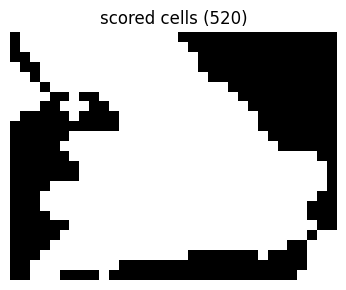

In [6]:
# Scored-cell mask: the global land mask plus a one-cell coastal dilation, the same
# construction as the other notebooks, so the 520 scored cells are the same cells.
gust_full = fields.get("i10fg", fields.get("fg10"))
LAND = np.ones((H, W), dtype=bool)
if MODE == "real":
    try:
        from global_land_mask import globe
        from scipy.ndimage import binary_dilation
        _LO, _LA = np.meshgrid(lons, lats)
        LAND = binary_dilation(globe.is_land(_LA, _LO), iterations=1)
        print("land mask: global_land_mask + 1-cell dilation (matches the other notebooks)")
    except Exception as _e:
        mean_gust = np.nanmean(gust_full, axis=0)
        LAND = mean_gust <= np.nanpercentile(mean_gust, 63)
        print("!" * 78)
        print("!!  global_land_mask unavailable, fell back to the gust percentile proxy:", _e)
        print("!!  The 520 scored cells will NOT match the other notebooks and the comparison")
        print("!!  in Table 4.2 will not be like for like. Install the package and re-run.")
        print("!" * 78)
N_LAND = int(LAND.sum())
print(f"Scored cells: {N_LAND} of {H*W}")
plt.figure(figsize=(4, 3)); plt.imshow(LAND[::-1], cmap="Greys_r"); plt.title(f"scored cells ({N_LAND})")
plt.axis("off"); plt.tight_layout(); plt.show()

In [7]:
# tstamp / train_end / val_end / is_train_t were set in the channel-building cell, because
# per-channel standardisation needs the training mask before the buffer is filled.

# per-cell P98 from the training period only (no leakage)
THR = np.nanpercentile(gust_full[is_train_t], CFG.POT_Q * 100, axis=0).astype(np.float32)  # (H,W)
print(f"Threshold: mean={THR[LAND].mean():.2f} m/s  range=[{THR[LAND].min():.1f}, {THR[LAND].max():.1f}]")

# forward rolling max over (t, t+LEAD]
FMAX = np.full_like(gust_full, -np.inf, dtype=np.float32)
for d in range(1, CFG.LEAD + 1):
    FMAX[:T - d] = np.maximum(FMAX[:T - d], gust_full[d:])
FMAX[T - CFG.LEAD:] = -np.inf                      # origins without a full lead window

OCC = (FMAX > THR[None]).astype(np.float32)                    # (T,H,W)
MAG = np.log(np.clip(FMAX - THR[None], 1e-3, None)).astype(np.float32)

# regime label: convective if the exceedance coincides with high CAPE / summer afternoon
if "cape" in fields:
    cape_f = np.zeros_like(gust_full)
    for d in range(1, CFG.LEAD + 1):
        cape_f[:T - d] = np.maximum(cape_f[:T - d], fields["cape"][d:])
    cape_ref = np.nanpercentile(fields["cape"][is_train_t], 90)
    REG = ((cape_f > cape_ref) & (OCC > 0.5)).astype(np.float32)
else:
    REG = np.zeros_like(OCC)

valid_t = np.arange(T) < (T - CFG.LEAD)
print(f"Base occurrence rate over scored cells: {OCC[valid_t][:, LAND].mean()*100:.2f}%")

Threshold: mean=19.08 m/s  range=[16.8, 23.9]
Base occurrence rate over scored cells: 8.10%


In [9]:
# origins: need HIST_HOURS of history behind and LEAD hours ahead
first_origin = CFG.HIST_HOURS
origins = np.arange(first_origin, T - CFG.LEAD, CFG.SAMPLE_STRIDE, dtype=np.int64)
o_time = tstamp[origins]
o_split = np.where(o_time <= train_end, 0, np.where(o_time <= val_end, 1, 2))
tr_o = origins[o_split == 0]; va_o = origins[o_split == 1]; te_o = origins[o_split == 2]
print(f"Origins  train {len(tr_o):,} | val {len(va_o):,} | test {len(te_o):,}")
for nm, o in [("train", tr_o), ("val", va_o), ("test", te_o)]:
    print(f"  {nm} positive rate: {OCC[o][:, LAND].mean()*100:.2f}%  "
          f"({len(o)*N_LAND:,} scored cell-hours)")

# MAE stage 1 uses EVERY training timestep, not only the strided origins
mae_o = np.arange(first_origin, T - CFG.LEAD, dtype=np.int64)
mae_o = mae_o[tstamp[mae_o] <= train_end]
print(f"MAE pretraining origins (unlabelled): {len(mae_o):,}")

Origins  train 23,498 | val 5,038 | test 5,031
  train positive rate: 8.42%  (12,218,960 scored cell-hours)
  val positive rate: 6.83%  (2,619,760 scored cell-hours)
  test positive rate: 7.68%  (2,616,120 scored cell-hours)
MAE pretraining origins (unlabelled): 70,492


In [10]:
# Free the raw fields now that the channel tensor is built; only the gust field (targets) and CAPE
# (regime label) are still needed, and those were copied out above.
for _k in list(fields):
    if _k not in ("i10fg", "fg10", "cape"):
        del fields[_k]
import gc; gc.collect()

pos_mask = (OCC[tr_o][:, LAND] > 0.5)
mag_tr = MAG[tr_o][:, LAND][pos_mask]
MAG_MEAN, MAG_STD = float(mag_tr.mean()), float(mag_tr.std() + 1e-6)
print(f"MAG_MEAN={MAG_MEAN:.3f} MAG_STD={MAG_STD:.3f}")

MAG_MEAN=0.567 MAG_STD=1.227


In [11]:
# physical tendency targets for the PDE residual
_gust_clean = np.nan_to_num(gust_full, nan=0.0, posinf=0.0, neginf=0.0)
DQ_TRUE = np.zeros_like(_gust_clean); DQ_TRUE[:-1] = _gust_clean[1:] - _gust_clean[:-1]
DQ_TRUE = np.nan_to_num(DQ_TRUE, nan=0.0, posinf=0.0, neginf=0.0)
assert np.isfinite(DQ_TRUE).all(), "DQ_TRUE still contains non finite values"
print(f"tendency targets: mean |dq| = {np.abs(DQ_TRUE).mean():.3f} m/s per hour")

LAND_T = torch.from_numpy(LAND.astype(np.float32))
HIST_OFFSETS = np.arange(-CFG.HIST_HOURS + CFG.HIST_STRIDE, 1, CFG.HIST_STRIDE)  # e.g. -45..0
assert len(HIST_OFFSETS) == HIST_T, (len(HIST_OFFSETS), HIST_T)

class FieldDS(Dataset):
    """Returns the full domain for one origin: x (HIST_T, C, H, W) and dense label maps."""
    def __init__(self, origins, labelled=True):
        self.o = np.asarray(origins); self.labelled = labelled
    def __len__(self):
        return len(self.o)
    def __getitem__(self, i):
        t = int(self.o[i])
        idx = t + HIST_OFFSETS
        x = torch.from_numpy(MAPS[idx].astype(np.float32))            # (HIST_T,C,H,W)
        if not self.labelled:
            return x
        y_occ = torch.from_numpy(OCC[t])                              # (H,W)
        y_mag = torch.from_numpy((MAG[t] - MAG_MEAN) / MAG_STD)
        y_reg = torch.from_numpy(REG[t])
        y_adv = torch.from_numpy(ADV_PHYS[t]) if ADV_PHYS is not None else torch.zeros_like(y_reg)
        y_dq  = torch.from_numpy(DQ_TRUE[t])
        return x, y_occ, y_mag, y_reg, y_adv, y_dq

NW = 2 if DEVICE.type == "cuda" else 0
dl_mae = DataLoader(FieldDS(mae_o, labelled=False), batch_size=CFG.MAE_BATCH, shuffle=True,
                    num_workers=NW, pin_memory=True, drop_last=True)
dl_tr = DataLoader(FieldDS(tr_o), batch_size=CFG.BATCH, shuffle=True,
                   num_workers=NW, pin_memory=True, drop_last=True)
dl_va = DataLoader(FieldDS(va_o), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)
dl_te = DataLoader(FieldDS(te_o), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)

_x, _o, _m, _r, _a, _d = next(iter(dl_tr))
print("batch:", _x.shape, _o.shape, _m.shape, _r.shape, _a.shape, _d.shape)

tendency targets: mean |dq| = 0.604 m/s per hour
batch: torch.Size([16, 16, 34, 25, 33]) torch.Size([16, 25, 33]) torch.Size([16, 25, 33]) torch.Size([16, 25, 33]) torch.Size([16, 25, 33]) torch.Size([16, 25, 33])


In [12]:
class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__(); self.p = p
    def forward(self, x):
        if self.p == 0.0 or not self.training:
            return x
        keep = 1 - self.p
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        mask = x.new_empty(shape).bernoulli_(keep)
        return x * mask / keep

class Attention(nn.Module):
    def __init__(self, d, heads, drop):
        super().__init__()
        self.h = heads; self.dh = d // heads; self.scale = self.dh ** -0.5
        self.qkv = nn.Linear(d, 3 * d, bias=True)
        self.proj = nn.Linear(d, d)
        self.drop = nn.Dropout(drop)
    def forward(self, x):                      # (B, N, d)
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        out = F.scaled_dot_product_attention(q, k, v,
                                             dropout_p=self.drop.p if self.training else 0.0)
        out = out.transpose(1, 2).reshape(B, N, D)
        return self.drop(self.proj(out))

class Mlp(nn.Module):
    def __init__(self, d, ratio, drop):
        super().__init__()
        hid = int(d * ratio)
        self.fc1 = nn.Linear(d, hid); self.fc2 = nn.Linear(hid, d); self.drop = nn.Dropout(drop)
    def forward(self, x):
        return self.drop(self.fc2(self.drop(F.gelu(self.fc1(x)))))

class STBlock(nn.Module):
    """One factorised space-time block: spatial attention, then temporal attention, then MLP."""
    def __init__(self, d, heads, ratio, drop, dpr, ls_init):
        super().__init__()
        self.n1 = nn.LayerNorm(d); self.att_s = Attention(d, heads, drop)
        self.n2 = nn.LayerNorm(d); self.att_t = Attention(d, heads, drop)
        self.n3 = nn.LayerNorm(d); self.mlp = Mlp(d, ratio, drop)
        self.g1 = nn.Parameter(ls_init * torch.ones(d))
        self.g2 = nn.Parameter(ls_init * torch.ones(d))
        self.g3 = nn.Parameter(ls_init * torch.ones(d))
        self.dp = DropPath(dpr)
    def forward(self, x, nt, ns):              # x: (B, nt*ns, d) laid out time-major
        B, N, D = x.shape
        # spatial: attend across the ns patches inside each timestep
        h = self.n1(x).reshape(B * nt, ns, D)
        h = self.att_s(h).reshape(B, N, D)
        x = x + self.dp(self.g1 * h)
        # temporal: attend across the nt timesteps at each patch location
        h = self.n2(x).reshape(B, nt, ns, D).transpose(1, 2).reshape(B * ns, nt, D)
        h = self.att_t(h).reshape(B, ns, nt, D).transpose(1, 2).reshape(B, N, D)
        x = x + self.dp(self.g2 * h)
        # channel mixing
        x = x + self.dp(self.g3 * self.mlp(self.n3(x)))
        return x

class PatchEmbed(nn.Module):
    def __init__(self, c, d, ph, pw, H, W):
        super().__init__()
        self.ph, self.pw = ph, pw
        self.gh = math.ceil(H / ph); self.gw = math.ceil(W / pw)
        self.pad_h = self.gh * ph - H; self.pad_w = self.gw * pw - W
        self.proj = nn.Conv2d(c, d, kernel_size=(ph, pw), stride=(ph, pw))
    def forward(self, x):                      # (B, T, C, H, W)
        B, Tt, C_, H_, W_ = x.shape
        x = x.reshape(B * Tt, C_, H_, W_)
        if self.pad_h or self.pad_w:
            x = F.pad(x, (0, self.pad_w, 0, self.pad_h), mode="replicate")
        x = self.proj(x)                       # (B*T, d, gh, gw)
        d = x.shape[1]
        x = x.flatten(2).transpose(1, 2)       # (B*T, ns, d)
        return x.reshape(B, Tt * self.gh * self.gw, d), self.gh, self.gw

class STEncoder(nn.Module):
    def __init__(self, c, cfg, H, W, nt):
        super().__init__()
        d = cfg.D_MODEL
        self.embed = PatchEmbed(c, d, cfg.PATCH_H, cfg.PATCH_W, H, W)
        self.gh, self.gw = self.embed.gh, self.embed.gw
        self.ns = self.gh * self.gw
        self.nt = nt
        self.pos_s = nn.Parameter(torch.zeros(1, 1, self.ns, d))
        self.pos_t = nn.Parameter(torch.zeros(1, nt, 1, d))
        nn.init.trunc_normal_(self.pos_s, std=0.02)
        nn.init.trunc_normal_(self.pos_t, std=0.02)
        dprs = torch.linspace(0, cfg.DROP_PATH, cfg.N_BLOCKS).tolist()
        self.blocks = nn.ModuleList([
            STBlock(d, cfg.N_HEADS, cfg.MLP_RATIO, cfg.DROPOUT, dprs[i], cfg.LAYER_SCALE)
            for i in range(cfg.N_BLOCKS)])
        self.norm = nn.LayerNorm(d)
    def tokens(self, x):
        h, gh, gw = self.embed(x)                                  # (B, nt*ns, d)
        B = x.shape[0]
        h = h.reshape(B, self.nt, self.ns, -1) + self.pos_s + self.pos_t
        return h.reshape(B, self.nt * self.ns, -1)
    def forward(self, x, keep=None):
        """keep: optional (B, nt*ns) bool of tokens to retain (MAE). Returns encoded tokens."""
        h = self.tokens(x)
        nt, ns = self.nt, self.ns
        if keep is not None:
            B, N, D = h.shape
            n_keep = int(keep[0].sum())
            idx = keep.nonzero(as_tuple=False)[:, 1].reshape(B, n_keep)
            h = torch.gather(h, 1, idx.unsqueeze(-1).expand(-1, -1, D))
            # with tokens dropped the space/time factorisation no longer applies -> joint attention
            for blk in self.blocks:
                h = blk(h, 1, n_keep)
            return self.norm(h), idx
        for blk in self.blocks:
            h = blk(h, nt, ns)
        return self.norm(h), None

In [13]:
class DenseHead(nn.Module):
    """Patch tokens -> full-resolution (H,W) maps for the three hurdle outputs."""
    def __init__(self, d, gh, gw, H, W, n_q, drop):
        super().__init__()
        self.gh, self.gw, self.H, self.W = gh, gw, H, W
        self.time_q = nn.Linear(d, 1)                       # attention pool over time
        self.mix = nn.Sequential(
            nn.Conv2d(d, d // 2, 3, padding=1), nn.GELU(), nn.Dropout2d(drop),
            nn.Conv2d(d // 2, d // 4, 3, padding=1), nn.GELU(),
        )
        self.occ = nn.Conv2d(d // 4, 1, 1)
        self.reg = nn.Conv2d(d // 4, 1, 1)
        self.mag = nn.Conv2d(d // 4, n_q, 1)
        self.sig = nn.Conv2d(d // 4, 1, 1)      # GPD scale, per cell and time
        self.dq  = nn.Conv2d(d // 4, 1, 1)      # one hour gust tendency, m/s
    def forward(self, h, nt, ns):                            # h: (B, nt*ns, d)
        B, N, D = h.shape
        h = h.reshape(B, nt, ns, D)
        w = torch.softmax(self.time_q(h).squeeze(-1), dim=1)  # (B,nt,ns)
        h = (w.unsqueeze(-1) * h).sum(1)                      # (B,ns,d)
        h = h.transpose(1, 2).reshape(B, D, self.gh, self.gw)
        h = F.interpolate(h, size=(self.H, self.W), mode="bilinear", align_corners=False)
        h = self.mix(h)
        occ = self.occ(h).squeeze(1)                          # (B,H,W)
        reg = self.reg(h).squeeze(1)
        raw = self.mag(h)                                     # (B,n_q,H,W)
        q0 = raw[:, :1]; dq = F.softplus(raw[:, 1:])
        mag = torch.cat([q0, q0 + torch.cumsum(dq, dim=1)], dim=1)   # monotone in q
        sigma = F.softplus(self.sig(h).squeeze(1)) + 1e-3             # GPD scale > 0
        dq = self.dq(h).squeeze(1)
        return occ, mag, reg, sigma, dq

class CIEWv4(nn.Module):
    def __init__(self, c, cfg, H, W, nt, base_rate=0.077):
        super().__init__()
        self.enc = STEncoder(c, cfg, H, W, nt)
        self.head = DenseHead(cfg.D_MODEL, self.enc.gh, self.enc.gw, H, W, N_Q, cfg.DROPOUT)
        # bias init at the base rate: standard for heavily imbalanced dense prediction
        nn.init.constant_(self.head.occ.bias, float(np.log(base_rate / (1 - base_rate))))
        # one learned GPD shape, bounded by tanh and started at the pooled POT estimate
        xi0 = float(np.arctanh(np.clip(cfg.XI_INIT / cfg.XI_CLAMP, -0.99, 0.99)))
        self.xi_raw = nn.Parameter(torch.tensor([xi0], dtype=torch.float32))
        self.xi_clamp = cfg.XI_CLAMP
    @property
    def xi(self):
        return self.xi_clamp * torch.tanh(self.xi_raw)
    def forward(self, x):
        h, _ = self.enc(x)
        occ, mag, reg, sigma, dq = self.head(h, self.enc.nt, self.enc.ns)
        return occ, mag, reg, sigma, self.xi, dq

BASE_RATE = float(OCC[tr_o][:, LAND].mean())
model = CIEWv4(C, CFG, H, W, HIST_T, BASE_RATE).to(DEVICE)
n_par = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"tokens: {model.enc.nt} time x {model.enc.ns} space = {model.enc.nt*model.enc.ns}")
print(f"trainable parameters: {n_par:,}  ({n_par/1e6:.1f} M)  vs v1 ~0.9 M")

tokens: 16 time x 99 space = 1584
trainable parameters: 8,911,883  (8.9 M)  vs v1 ~0.9 M


In [14]:
class MAE(nn.Module):
    def __init__(self, enc, cfg, c, ph, pw):
        super().__init__()
        self.enc = enc
        d, dd = cfg.D_MODEL, cfg.MAE_DEC_DIM
        self.patch_dim = c * ph * pw
        self.dec_embed = nn.Linear(d, dd)
        self.mask_tok = nn.Parameter(torch.zeros(1, 1, dd))
        nn.init.trunc_normal_(self.mask_tok, std=0.02)
        self.dec_pos = nn.Parameter(torch.zeros(1, enc.nt * enc.ns, dd))
        nn.init.trunc_normal_(self.dec_pos, std=0.02)
        self.dec_blocks = nn.ModuleList([
            STBlock(dd, 4, 4.0, 0.0, 0.0, 1.0) for _ in range(cfg.MAE_DEC_BLOCKS)])
        self.dec_norm = nn.LayerNorm(dd)
        self.pred = nn.Linear(dd, self.patch_dim)

    def patchify(self, x, ph, pw):
        """(B,T,C,H,W) -> (B, T*ns, C*ph*pw) matching the encoder's token order."""
        B, Tt, C_, H_, W_ = x.shape
        x = x.reshape(B * Tt, C_, H_, W_)
        pad_h = self.enc.embed.pad_h; pad_w = self.enc.embed.pad_w
        if pad_h or pad_w:
            x = F.pad(x, (0, pad_w, 0, pad_h), mode="replicate")
        gh, gw = self.enc.gh, self.enc.gw
        x = x.reshape(B * Tt, C_, gh, ph, gw, pw)
        x = x.permute(0, 2, 4, 1, 3, 5).reshape(B * Tt, gh * gw, C_ * ph * pw)
        return x.reshape(B, Tt * gh * gw, -1)

    def forward(self, x, mask_ratio):
        B = x.shape[0]
        N = self.enc.nt * self.enc.ns
        n_keep = max(1, int(N * (1 - mask_ratio)))
        noise = torch.rand(B, N, device=x.device)
        shuffle = noise.argsort(dim=1)
        keep_idx = shuffle[:, :n_keep]
        keep = torch.zeros(B, N, dtype=torch.bool, device=x.device)
        keep.scatter_(1, keep_idx, True)

        lat, idx = self.enc(x, keep=keep)                      # (B, n_keep, d)
        h = self.dec_embed(lat)
        full = self.mask_tok.expand(B, N, -1).clone()
        full = full.scatter(1, idx.unsqueeze(-1).expand(-1, -1, h.shape[-1]), h.to(full.dtype))
        full = full + self.dec_pos
        for blk in self.dec_blocks:
            full = blk(full, 1, N)
        pred = self.pred(self.dec_norm(full))                  # (B,N,patch_dim)

        target = self.patchify(x, self.enc.embed.ph, self.enc.embed.pw)
        loss = ((pred - target) ** 2).mean(dim=-1)             # (B,N)
        masked = ~keep
        return (loss * masked).sum() / masked.sum().clamp(min=1), pred, keep

def cosine_lr(opt, base_lrs, step, total, warmup):
    if step < warmup:
        f = step / max(1, warmup)
    else:
        p = (step - warmup) / max(1, total - warmup)
        f = 0.5 * (1 + math.cos(math.pi * min(1.0, p)))
    for g, b in zip(opt.param_groups, base_lrs):
        g["lr"] = b * f
    return f

legacy cache mae_encoder.pt matches this architecture -> reusing it
REUSING cached masked autoencoder: /content/drive/MyDrive/MSc Dissertation/ciew_v5_cache/mae_encoder.pt
Pretraining is skipped. The encoder is valid for this run because it never saw the
land mask or the physics targets, and the channel stack is unchanged.
reusing cached MAE encoder -> /content/drive/MyDrive/MSc Dissertation/ciew_v5_cache/mae_encoder.pt


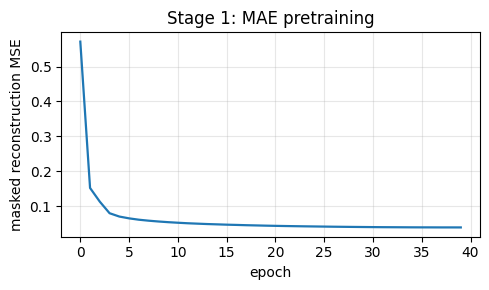

In [15]:
RUN_MAE = True          # set False to skip straight to the scratch control
# The MAE cache is keyed to the architecture that produced it.
# Changing the channel count, D_MODEL, N_BLOCKS, HIST_STRIDE or the patch size
# changes the patch embedding and the temporal position table; load_state_dict
# then raises inside the fine-tuning cell, after the expensive data build.
#   1. the working filename carries the architecture, so a changed architecture
#      gets its own file and can never collide with an older one
#   2. a legacy unsuffixed mae_encoder.pt is adopted only if every tensor shape
#      matches, so an existing pretrained encoder is never wasted.
_arch = f"C{C}_D{CFG.D_MODEL}_B{CFG.N_BLOCKS}_T{HIST_T}_P{CFG.PATCH_H}x{CFG.PATCH_W}"
MAE_CKPT = CFG.CACHE / f"mae_encoder_{_arch}.pt"
_legacy = CFG.CACHE / "mae_encoder.pt"
if not MAE_CKPT.exists() and _legacy.exists():
    try:
        _ref = STEncoder(C, CFG, H, W, HIST_T).state_dict()
        _got = torch.load(_legacy, map_location="cpu")["enc"]
        if all(k in _got and tuple(_got[k].shape) == tuple(v.shape) for k, v in _ref.items()):
            MAE_CKPT = _legacy
            print(f"legacy cache {_legacy.name} matches this architecture -> reusing it", flush=True)
        else:
            _bad = [k for k, v in _ref.items()
                    if k in _got and tuple(_got[k].shape) != tuple(v.shape)]
            print("!" * 78)
            print("!! legacy mae_encoder.pt does NOT match this architecture - ignoring it.")
            for _k in _bad[:4]:
                print(f"!!   {_k}: cached {tuple(_got[_k].shape)} vs now {tuple(_ref[_k].shape)}")
            print(f"!! pretraining will run and save to mae_encoder_{_arch}.pt")
            print("!" * 78, flush=True)
        del _ref, _got
    except Exception as _e:
        print("could not validate the legacy cache, ignoring it:", repr(_e), flush=True)
if MAE_CKPT.exists():
    print("=" * 78)
    print(f"REUSING cached masked autoencoder: {MAE_CKPT}")
    print("Pretraining is skipped. The encoder is valid for this run because it never saw the")
    print("land mask or the physics targets, and the channel stack is unchanged.")
    print("=" * 78, flush=True)
else:
    print(f"No cached encoder at {MAE_CKPT} -> pretraining will run (about 5.4 hours).", flush=True)

if RUN_MAE and not MAE_CKPT.exists():
    enc_pt = STEncoder(C, CFG, H, W, HIST_T).to(DEVICE)
    mae = MAE(enc_pt, CFG, C, CFG.PATCH_H, CFG.PATCH_W).to(DEVICE)
    opt = torch.optim.AdamW(mae.parameters(), lr=CFG.MAE_LR, weight_decay=0.05, betas=(0.9, 0.95))
    base_lrs = [g["lr"] for g in opt.param_groups]
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    total = CFG.MAE_EPOCHS * len(dl_mae); warm = int(0.05 * total); step = 0
    hist_mae = []

    print(f"MAE pretraining: {CFG.MAE_EPOCHS} epochs x {len(dl_mae)} steps "
          f"on {len(mae_o):,} unlabelled origins", flush=True)
    for ep in range(CFG.MAE_EPOCHS):
        mae.train(); run = 0.0; n = 0; t0 = time.time()
        for xb in dl_mae:
            xb = xb.to(DEVICE, non_blocking=True)
            cosine_lr(opt, base_lrs, step, total, warm); step += 1
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=AMP):
                loss, _, _ = mae(xb, CFG.MAE_MASK_RATIO)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(mae.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            run += loss.item() * xb.shape[0]; n += xb.shape[0]
        hist_mae.append(run / n)
        print(f"  ep {ep+1:3d}/{CFG.MAE_EPOCHS}  recon MSE {run/n:.5f}  ({time.time()-t0:.0f}s)",
              flush=True)

    torch.save({"enc": enc_pt.state_dict(), "hist": hist_mae}, MAE_CKPT)
    print("saved ->", MAE_CKPT)
elif MAE_CKPT.exists():
    hist_mae = torch.load(MAE_CKPT, map_location="cpu").get("hist", [])
    print("reusing cached MAE encoder ->", MAE_CKPT)
else:
    hist_mae = []
    print("MAE skipped.")

if hist_mae:
    plt.figure(figsize=(5, 3))
    plt.plot(hist_mae, lw=1.6); plt.xlabel("epoch"); plt.ylabel("masked reconstruction MSE")
    plt.title("Stage 1: MAE pretraining"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [16]:
QT = torch.tensor(CFG.QUANTILES, dtype=torch.float32, device=DEVICE).view(1, N_Q, 1, 1)
LAND_D = LAND_T.to(DEVICE)

def focal_bce_dense(logit, target, mask, gamma):
    p = torch.sigmoid(logit)
    ce = F.binary_cross_entropy_with_logits(logit, target, reduction="none")
    pt = p * target + (1 - p) * (1 - target)
    loss = ((1 - pt) ** gamma) * ce
    return (loss * mask).sum() / mask.sum().clamp(min=1)

def pinball_dense(q_pred, target, weight):
    # q_pred (B,N_Q,H,W), target (B,H,W), weight (B,H,W)
    e = target.unsqueeze(1) - q_pred
    loss = torch.maximum(QT * e, (QT - 1) * e).mean(dim=1)
    return (loss * weight).sum() / weight.sum().clamp(min=1)

def gpd_nll_dense(sigma, xi, excess, weight, out_penalty):
    """Negative log-likelihood of GPD(sigma, xi) on true exceedances.

    Points falling outside the distribution's support (1 + xi*y/sigma <= 0, which can happen while
    xi < 0) are handled explicitly: they receive the exponential-tail likelihood plus a *bounded*
    penalty. Clamping the argument instead, as the earlier HEICH models did, produces an unbounded
    spike in the loss that pushes the learned shape upward.
    """
    s_ = sigma.clamp(min=1e-3)
    y = excess.clamp(min=0.0)
    xi_s = xi.view(1, 1, 1).expand_as(y)
    small = xi_s.abs() < 1e-4
    z = 1.0 + xi_s * y / s_
    inside = z > 1e-6
    zc = z.clamp(min=1e-6)
    xi_safe = torch.where(small, torch.ones_like(xi_s), xi_s)
    nll_gpd = torch.log(s_) + (1.0 + 1.0 / xi_safe) * torch.log(zc)
    nll_exp = torch.log(s_) + y / s_
    nll = torch.where(small, nll_exp, nll_gpd)
    nll = torch.where(inside, nll, nll_exp + out_penalty)
    w = weight
    return (nll * w).sum() / w.sum().clamp(min=1)

def physics_terms(dq_pred, dq_true, adv, mask, dt):
    """Auxiliary tendency term and the advection residual, restricted to scored cells."""
    w = mask.unsqueeze(0)
    l_aux = (((dq_pred - dq_true)**2) * w).sum() / w.sum().clamp(min=1) / max(dq_pred.size(0), 1)
    l_phys = (((dq_pred - adv*dt)**2) * w).sum() / w.sum().clamp(min=1) / max(dq_pred.size(0), 1)
    return l_aux, l_phys

class EMA:
    def __init__(self, model, decay):
        self.decay = decay
        self.shadow = {k: v.detach().clone().float() for k, v in model.state_dict().items()}
    @torch.no_grad()
    def update(self, model):
        for k, v in model.state_dict().items():
            if v.dtype.is_floating_point:
                self.shadow[k].mul_(self.decay).add_(v.detach().float(), alpha=1 - self.decay)
            else:
                self.shadow[k] = v.detach().clone()
    def copy_to(self, model):
        model.load_state_dict({k: v.to(dtype=dict(model.state_dict())[k].dtype)
                               for k, v in self.shadow.items()})

In [17]:
@torch.no_grad()
def predict_dense(net, loader):
    """Returns flattened per-(origin, scored-cell) arrays, matching the evaluation set of the other models."""
    net.eval()
    P, Yo, Mq, Yr = [], [], [], []
    land_np = LAND
    for batch in loader:
        xb, yo, ym, yr, ya, yd = batch
        xb = xb.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=AMP):
            o, m, r, sg, xi_c, _ = net(xb)
        p = torch.sigmoid(o.float()).cpu().numpy()
        mm = m.float().cpu().numpy()
        P.append(p[:, land_np]); Yo.append(yo.numpy()[:, land_np])
        Mq.append(mm[:, :, land_np]); Yr.append(yr.numpy()[:, land_np])
    return (np.concatenate(P).ravel(), np.concatenate(Yo).ravel(),
            np.concatenate(Mq, axis=0), np.concatenate(Yr).ravel())

VA_LOGEXC = MAG[va_o][:, LAND].ravel()          # observed log-excess at validation rows
VA_EXC = np.exp(VA_LOGEXC)

def val_mag_crps(mq_va, y_va):
    # CRPS over the central 80% of the predictive distribution, on validation
    # exceedances only. Same estimator as the strength section, so the checkpoint
    # is selected on the quantity that is later reported.
    pos = np.asarray(y_va).ravel() > 0.5
    if pos.sum() < 100:
        return np.nan
    q = np.transpose(mq_va, (0, 2, 1)).reshape(-1, mq_va.shape[1])[pos]
    q = np.sort(np.exp(q * MAG_STD + MAG_MEAN), axis=1)
    obs = VA_EXC[pos]
    d = obs[:, None] - q
    tau = QLEVELS[None, :]
    pb = np.mean(np.maximum(tau * d, (tau - 1.0) * d), axis=0)
    return float(2.0 * (np.trapezoid(pb, QLEVELS) if hasattr(np, "trapezoid")
                        else np.trapz(pb, QLEVELS)))

def train_model(net, tag, pretrained_enc=None, epochs=None, dl_train=None, verbose=True):
    epochs = epochs or CFG.EPOCHS
    dl_train = dl_train or dl_tr
    if pretrained_enc is not None:
        missing = net.enc.load_state_dict(pretrained_enc, strict=False)
        if verbose:
            print(f"[{tag}] loaded pretrained encoder "
                  f"(missing {len(missing.missing_keys)}, unexpected {len(missing.unexpected_keys)})")

    head_params = [p for n_, p in net.named_parameters() if n_.startswith("head")]
    trunk_params = [p for n_, p in net.named_parameters() if not n_.startswith("head")]
    opt = torch.optim.AdamW(
        [{"params": trunk_params, "lr": CFG.LR},
         {"params": head_params,  "lr": CFG.LR_HEAD}],
        weight_decay=CFG.WEIGHT_DECAY, betas=(0.9, 0.95))
    base_lrs = [g["lr"] for g in opt.param_groups]
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)

    total = epochs * len(dl_train); warm = int(CFG.WARMUP_FRAC * total); step = 0
    best, best_state, bad, hist = -np.inf, None, 0, []
    # A second checkpoint is kept, selected on validation magnitude skill, so that
    # magnitude is not reported from the checkpoint chosen for occurrence.
    best_mag, best_mag_state, best_mag_ep = np.inf, None, -1
    freeze = CFG.FREEZE_EPOCHS if pretrained_enc is not None else 0

    for ep in range(epochs):
        if freeze:
            for p in trunk_params:
                p.requires_grad = (ep >= freeze)
        net.train(); run = 0.0; n = 0; t0 = time.time()
        for xb, yo, ym, yr, ya, yd in dl_train:
            xb = xb.to(DEVICE, non_blocking=True)
            yo = yo.to(DEVICE, non_blocking=True); ym = ym.to(DEVICE, non_blocking=True)
            yr = yr.to(DEVICE, non_blocking=True)
            ya = ya.to(DEVICE, non_blocking=True); yd = yd.to(DEVICE, non_blocking=True)
            cosine_lr(opt, base_lrs, step, total, warm); step += 1
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=AMP):
                o, m, r, sg, xi_c, dqp = net(xb)
                mask = LAND_D.unsqueeze(0).expand_as(yo)
                l_occ = focal_bce_dense(o, yo, mask, CFG.FOCAL_GAMMA)
                l_mag = pinball_dense(m, ym, mask * yo)
                l_reg = focal_bce_dense(r, yr, mask, 0.0)
                # GPD tail on the true exceedances only. ym is the normalised log-excess
                # so invert the transform to recover the excess in m/s.
                exc_raw = torch.exp(ym * MAG_STD + MAG_MEAN)
                l_gpd = (gpd_nll_dense(sg, xi_c, exc_raw, mask * yo, CFG.GPD_OUT_PENALTY)
                         if CFG.USE_GPD else torch.zeros((), device=o.device))
                if CFG.USE_PHYSICS:
                    l_aux, l_phys = physics_terms(dqp, yd, ya, LAND_D, CFG.DT_HOURS)
                else:
                    l_aux = l_phys = torch.zeros((), device=o.device)
                loss = (l_occ + CFG.LAMBDA_MAG * l_mag + CFG.LAMBDA_REG * l_reg + CFG.LAMBDA_GPD * l_gpd
                        + CFG.LAMBDA_AUX * l_aux + CFG.LAMBDA_PHYS * l_phys)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            run += loss.item() * xb.shape[0]; n += xb.shape[0]

        from sklearn.metrics import average_precision_score
        p_va, y_va, mq_va, _ = predict_dense(net, dl_va)
        ap = average_precision_score(y_va, p_va)
        crps_va = val_mag_crps(mq_va, y_va)
        hist.append({"epoch": ep + 1, "loss": run / n, "val_pr_auc": ap,
                     "val_mag_crps": crps_va})
        if verbose:
            print(f"[{tag}] ep {ep+1:3d}/{epochs}  loss {run/n:.4f}  val PR-AUC {ap:.4f}  "
                  f"val mag CRPS {crps_va:.4f}  ({time.time()-t0:.0f}s)", flush=True)

        improved = False
        if ap > best + 1e-5:
            best, improved = ap, True
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        if np.isfinite(crps_va) and crps_va < best_mag - 1e-9:
            best_mag, best_mag_ep, improved = crps_va, ep + 1, True
            best_mag_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        # stop only once NEITHER objective has improved, so the magnitude head is
        # not cut off by the occurrence head plateauing first
        bad = 0 if improved else bad + 1
        if bad >= CFG.PATIENCE:
            if verbose: print(f"[{tag}] early stop at epoch {ep+1}")
            break

    if best_state is not None:
        net.load_state_dict(best_state)
    net._mag_state = best_mag_state          # carried alongside, loaded only for magnitude
    net._mag_crps = best_mag
    net._mag_epoch = best_mag_ep
    if verbose:
        print(f"[{tag}] occurrence checkpoint: val PR-AUC {best:.4f} | "
              f"magnitude checkpoint: epoch {best_mag_ep}, val CRPS {best_mag:.4f}", flush=True)
    return net, pd.DataFrame(hist), best

In [18]:
RESULTS = {}

# A. pretrained
ckpt = torch.load(MAE_CKPT, map_location="cpu") if MAE_CKPT.exists() else None
net_pre = CIEWv4(C, CFG, H, W, HIST_T, BASE_RATE).to(DEVICE)
net_pre, hist_pre, best_pre = train_model(
    net_pre, "MAE-pretrained", pretrained_enc=ckpt["enc"] if ckpt else None)
RESULTS["CIEW v4 (MAE-pretrained)"] = net_pre
print(f"\nbest val PR-AUC, pretrained: {best_pre:.4f}")

[MAE-pretrained] loaded pretrained encoder (missing 0, unexpected 0)
[MAE-pretrained] ep   1/45  loss 1.9577  val PR-AUC 0.4175  val mag CRPS 1.2205  (55s)
[MAE-pretrained] ep   2/45  loss 1.6010  val PR-AUC 0.5060  val mag CRPS 1.2996  (56s)
[MAE-pretrained] ep   3/45  loss 1.5495  val PR-AUC 0.5796  val mag CRPS 1.2257  (54s)
[MAE-pretrained] ep   4/45  loss 1.5250  val PR-AUC 0.6144  val mag CRPS 1.1598  (114s)
[MAE-pretrained] ep   5/45  loss 1.4816  val PR-AUC 0.6213  val mag CRPS 1.2439  (114s)
[MAE-pretrained] ep   6/45  loss 1.4363  val PR-AUC 0.6321  val mag CRPS 1.2478  (114s)
[MAE-pretrained] ep   7/45  loss 1.3959  val PR-AUC 0.6289  val mag CRPS 1.1849  (114s)
[MAE-pretrained] ep   8/45  loss 1.3541  val PR-AUC 0.6081  val mag CRPS 1.1938  (114s)
[MAE-pretrained] ep   9/45  loss 1.3203  val PR-AUC 0.6100  val mag CRPS 1.2527  (114s)
[MAE-pretrained] ep  10/45  loss 1.2865  val PR-AUC 0.6001  val mag CRPS 1.2710  (114s)
[MAE-pretrained] ep  11/45  loss 1.2498  val PR-AUC 0.

[scratch] ep   1/45  loss 1.9517  val PR-AUC 0.3034  val mag CRPS 1.2172  (115s)
[scratch] ep   2/45  loss 1.6346  val PR-AUC 0.3859  val mag CRPS 1.2305  (115s)
[scratch] ep   3/45  loss 1.6009  val PR-AUC 0.4922  val mag CRPS 1.2355  (115s)
[scratch] ep   4/45  loss 1.5517  val PR-AUC 0.5233  val mag CRPS 1.2183  (115s)
[scratch] ep   5/45  loss 1.5220  val PR-AUC 0.5818  val mag CRPS 1.2074  (114s)
[scratch] ep   6/45  loss 1.5022  val PR-AUC 0.5864  val mag CRPS 1.1752  (115s)
[scratch] ep   7/45  loss 1.4731  val PR-AUC 0.5923  val mag CRPS 1.2483  (115s)
[scratch] ep   8/45  loss 1.4492  val PR-AUC 0.6076  val mag CRPS 1.2326  (115s)
[scratch] ep   9/45  loss 1.4202  val PR-AUC 0.6037  val mag CRPS 1.1611  (115s)
[scratch] ep  10/45  loss 1.3929  val PR-AUC 0.5938  val mag CRPS 1.1855  (115s)
[scratch] ep  11/45  loss 1.3688  val PR-AUC 0.6082  val mag CRPS 1.2702  (116s)
[scratch] ep  12/45  loss 1.3340  val PR-AUC 0.5980  val mag CRPS 1.2963  (115s)
[scratch] ep  13/45  loss 1.

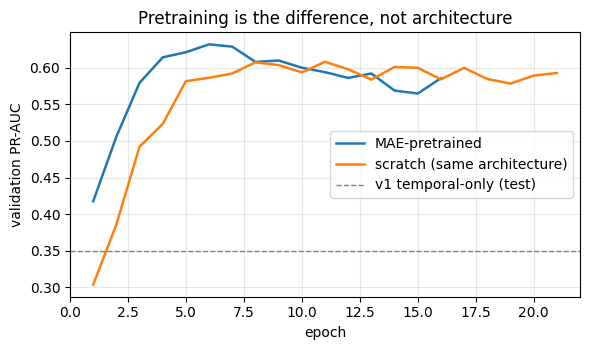

In [19]:
# B. scratch control: identical architecture, random init
torch.manual_seed(0)
net_scr = CIEWv4(C, CFG, H, W, HIST_T, BASE_RATE).to(DEVICE)
net_scr, hist_scr, best_scr = train_model(net_scr, "scratch", pretrained_enc=None)
RESULTS["CIEW v4 (scratch)"] = net_scr
print(f"\nbest val PR-AUC — pretrained {best_pre:.4f} | scratch {best_scr:.4f} "
      f"| delta {best_pre-best_scr:+.4f}")

plt.figure(figsize=(6, 3.6))
plt.plot(hist_pre.epoch, hist_pre.val_pr_auc, label="MAE-pretrained", lw=1.8)
plt.plot(hist_scr.epoch, hist_scr.val_pr_auc, label="scratch (same architecture)", lw=1.8)
plt.axhline(0.349, ls="--", c="grey", lw=1, label="v1 temporal-only (test)")
plt.xlabel("epoch"); plt.ylabel("validation PR-AUC"); plt.legend(); plt.grid(alpha=.3)
plt.title("Pretraining is the difference, not architecture")
plt.tight_layout(); plt.show()

In [20]:
# Severity is scored from the checkpoint selected on validation severity CRPS.
# Two calibrations are fitted on validation exceedances only: a per-quantile shift
# (crossings repaired with a running maximum) and a split-conformal band on the
# outer interval, whose radius may be negative when the raw band over-covers.

def per_quantile_shift(q_val, y_val, taus):
    return np.array([np.quantile(y_val - q_val[:, k], taus[k]) for k in range(len(taus))])

def apply_shift(q, delta):
    # running maximum keeps the quantiles ordered without permuting them
    return np.maximum.accumulate(q + delta[None, :], axis=1)

def conformal_radius(q_val, y_val, alpha):
    E = np.maximum(q_val[:, 0] - y_val, y_val - q_val[:, -1])
    n = E.size
    lvl = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(E, lvl))

@torch.no_grad()
def mag_quantiles(net, loader):
    net.eval()
    Q, Y = [], []
    for xb, yo, ym, yr, ya, yd in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=AMP):
            _, m, _, _, _, _ = net(xb)
        Q.append(m.float().cpu().numpy()[:, :, LAND])
        Y.append(yo.numpy()[:, LAND])
    q = np.concatenate(Q, 0)
    q = np.transpose(q, (0, 2, 1)).reshape(-1, q.shape[1])
    return np.maximum.accumulate(np.exp(q * MAG_STD + MAG_MEAN), axis=1), np.concatenate(Y).ravel()

TE_EXC = np.exp(MAG[te_o][:, LAND].ravel())
ALPHA = 1.0 - (QLEVELS[-1] - QLEVELS[0])       # 0.20 for a q10-q90 band
MAG_CAL = {}
print()

for _nm, _net in RESULTS.items():
    _occ_state = {k: v.detach().cpu().clone() for k, v in _net.state_dict().items()}
    if getattr(_net, "_mag_state", None) is not None:
        _net.load_state_dict(_net._mag_state)
        _src = f"magnitude checkpoint, epoch {_net._mag_epoch}"
    else:
        _src = "occurrence checkpoint (none stored for magnitude)"

    _qva, _yva = mag_quantiles(_net, dl_va)
    _qte, _yte = mag_quantiles(_net, dl_te)
    _net.load_state_dict(_occ_state)

    _pv, _pt = _yva > 0.5, _yte > 0.5
    _ova, _ote = VA_EXC[_pv], TE_EXC[_pt]
    _qv, _qt = _qva[_pv], _qte[_pt]

    _delta = per_quantile_shift(_qv, _ova, QLEVELS)
    _q_shift = apply_shift(_qt, _delta)
    _rad = conformal_radius(_qv, _ova, ALPHA)
    _q_band = _qt.copy()
    _q_band[:, 0] -= _rad
    _q_band[:, -1] += _rad
    _q_band = np.maximum.accumulate(_q_band, axis=1)

    # Held-out check. The shift is fitted on validation, so it always looks good
    # there. Fit it on the first half of the validation exceedances and score the
    # second half: if it does not help out of sample, it will not help on test.
    _h = _ova.size // 2
    _dA = per_quantile_shift(_qv[:_h], _ova[:_h], QLEVELS)
    def _crps_(o, q):
        d = o[:, None] - q; t = QLEVELS[None, :]
        pb = np.mean(np.maximum(t * d, (t - 1.0) * d), axis=0)
        return float(2.0 * (np.trapezoid(pb, QLEVELS) if hasattr(np, "trapezoid")
                            else np.trapz(pb, QLEVELS)))
    _rB = _crps_(_ova[_h:], _qv[_h:])
    _sB = _crps_(_ova[_h:], apply_shift(_qv[_h:], _dA))
    _verdict = ("shift helps out of sample, quote the calibrated row"
                if _sB < _rB else
                "SHIFT DOES NOT HELP OUT OF SAMPLE, quote the raw row")
    print(f"   held-out validation CRPS: raw {_rB:.4f} -> shifted {_sB:.4f}   {_verdict}")
    _cov = lambda q: float(np.mean((_ote >= q[:, 0]) & (_ote <= q[:, -1])))
    MAG_CAL[_nm] = dict(q_raw=_qt, q_shift=_q_shift, q_band=_q_band, obs=_ote,
                        delta=_delta, radius=_rad, src=_src)
    print(f"{_nm}   [{_src}]")
    print("   per-quantile shift (m/s): "
          + "  ".join(f"{t:.2f}:{d:+.3f}" for t, d in zip(QLEVELS, _delta)))
    print(f"   conformal band radius: {_rad:.3f} m/s")
    print(f"   q{int(QLEVELS[0]*100)}-q{int(QLEVELS[-1]*100)} coverage on test: "
          f"raw {_cov(_qt):.3f} | shifted {_cov(_q_shift):.3f} | "
          f"conformal band {_cov(_q_band):.3f}   (nominal {1-ALPHA:.2f})")


   held-out validation CRPS: raw 1.1952 -> shifted 1.1848   shift helps out of sample, quote the calibrated row
CIEW v4 (MAE-pretrained)   [magnitude checkpoint, epoch 4]
   per-quantile shift (m/s): 0.10:-0.030  0.25:-0.058  0.50:+0.142  0.75:+0.418  0.90:+1.021
   conformal band radius: 0.207 m/s
   q10-q90 coverage on test: raw 0.722 | shifted 0.803 | conformal band 0.793   (nominal 0.80)
   held-out validation CRPS: raw 1.2992 -> shifted 1.2868   shift helps out of sample, quote the calibrated row
CIEW v4 (scratch)   [magnitude checkpoint, epoch 9]
   per-quantile shift (m/s): 0.10:-0.050  0.25:+0.021  0.50:+0.151  0.75:+0.516  0.90:+0.985
   conformal band radius: 0.182 m/s
   q10-q90 coverage on test: raw 0.732 | shifted 0.817 | conformal band 0.798   (nominal 0.80)


In [21]:
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression

def sedi(y, p, thr):
    yh = (p >= thr).astype(int)
    H_ = ((yh == 1) & (y == 1)).sum(); M = ((yh == 0) & (y == 1)).sum()
    Fa = ((yh == 1) & (y == 0)).sum(); Cn = ((yh == 0) & (y == 0)).sum()
    hr = H_ / max(H_ + M, 1); far = Fa / max(Fa + Cn, 1)
    hr = min(max(hr, 1e-6), 1 - 1e-6); far = min(max(far, 1e-6), 1 - 1e-6)
    num = (math.log(far) - math.log(hr) - math.log(1 - far) + math.log(1 - hr))
    den = (math.log(far) + math.log(hr) + math.log(1 - far) + math.log(1 - hr))
    return num / den if den != 0 else 0.0

def occ_metrics(y, p, name, thr=None):
    base = y.mean()
    bs_clim = brier_score_loss(y, np.full_like(p, base))
    if thr is None:                          # fall back only if no operating
        thr = np.quantile(p, 1 - base)       # point was chosen on validation
    return {"Model": name,
            "ROC AUC": roc_auc_score(y, p),
            "PR AUC": average_precision_score(y, p),
            "Brier skill": 1 - brier_score_loss(y, p) / bs_clim,
            "SEDI": sedi(y, p, thr)}

rows = []
rows.append({"Model": "Climatology", "ROC AUC": 0.5, "PR AUC": float(OCC[te_o][:, LAND].mean()),
             "Brier skill": 0.0, "SEDI": 0.0})

CAL, PRED_TEST = {}, {}
for name, net in RESULTS.items():
    p_va, y_va, _, _ = predict_dense(net, dl_va)
    p_te, y_te, mq_te, yr_te = predict_dense(net, dl_te)
    iso = IsotonicRegression(out_of_bounds="clip").fit(p_va, y_va)
    p_cal = iso.predict(p_te)
    CAL[name] = iso; PRED_TEST[name] = (p_te, p_cal, y_te, mq_te, yr_te)
    # the alarm rate is matched to the base rate on validation and the resulting
    # threshold is applied to test, as for the other models
    _bv = y_va.mean()
    thr_raw = float(np.quantile(p_va, 1 - _bv))
    thr_cal = float(np.quantile(iso.predict(p_va), 1 - _bv))
    rows.append(occ_metrics(y_te, p_te, f"{name}, raw", thr_raw))
    rows.append(occ_metrics(y_te, p_cal, f"{name}, calibrated", thr_cal))

tab = pd.DataFrame(rows).set_index("Model").round(4)
print(f"\nTest period: {len(te_o):,} origins x {N_LAND} cells = {len(te_o)*N_LAND:,} cell-hours")
print(f"Base rate: {OCC[te_o][:, LAND].mean()*100:.2f}%\n")
display(tab)


Test period: 5,031 origins x 520 cells = 2,616,120 cell-hours
Base rate: 7.68%



,ROC AUC,PR AUC,Brier skill,SEDI
Model,,,,
Climatology,0.5000,0.0768,0.0000,0.0000
"CIEW v4 (MAE-pretrained), raw",0.9160,0.6271,0.1856,0.7433
"CIEW v4 (MAE-pretrained), calibrated",0.9159,0.6232,0.3812,0.7441
"CIEW v4 (scratch), raw",0.9164,0.6067,0.1767,0.7287
"CIEW v4 (scratch), calibrated",0.9163,0.6031,0.3616,0.7337


In [22]:
# inputs for the severity verification
# magnitude comes from the magnitude checkpoint. Raw and calibrated are both
# reported so the effect of calibration is visible rather than assumed.
_S_TAUS  = getattr(CFG, "QUANTILES", (0.1, 0.25, 0.5, 0.75, 0.9))
_S_OBS   = list(MAG_CAL.values())[0]["obs"]
_s_mtr, _s_otr = MAG[tr_o][:, LAND], OCC[tr_o][:, LAND]
_S_TRAIN = np.exp(_s_mtr[_s_otr > 0.5])
_S_PRED  = {}
for _snm, _d in MAG_CAL.items():
    _short = _snm.replace("CIEW v4 ", "").replace("(", "").replace(")", "")
    _S_PRED[f"{_short}: raw"] = _d["q_raw"]
    _S_PRED[f"{_short}: shifted"] = _d["q_shift"]

# Severity on true events: MAE, pinball loss and CRPS against the climatology of
# training-period excesses. The quantile grid spans 0.1-0.9, so the CRPS here is
# restricted to the central 80% (CRPS[10-90]). Skill % = 100 * (1 - model / clim).
try:
    _tau = np.asarray(_S_TAUS, dtype=np.float64)
    _obs = np.asarray(_S_OBS, dtype=np.float64).ravel()
    _tr = np.asarray(_S_TRAIN, dtype=np.float64).ravel()
    _tr = _tr[np.isfinite(_tr)]
    assert _obs.size > 50, f"only {_obs.size} scored events"

    def _pinball_vec(obs, q, tau):
        """Mean pinball loss per quantile level. obs (n,), q (n,K), tau (K,)."""
        d = obs[:, None] - q
        return np.mean(np.maximum(tau[None, :] * d, (tau[None, :] - 1.0) * d), axis=0)

    def _crps_from_pinball(pb, tau):
        """CRPS = 2 * integral of pinball over tau, trapezoid on the given grid."""
        return 2.0 * np.trapezoid(pb, tau) if hasattr(np, "trapezoid") \
            else 2.0 * np.trapz(pb, tau)

    # climatological reference: the same quantiles for every event
    _cq = np.quantile(_tr, _tau)
    _clim = np.repeat(_cq[None, :], _obs.size, axis=0)
    _pb_c = _pinball_vec(_obs, _clim, _tau)
    _crps_c = _crps_from_pinball(_pb_c, _tau)
    _mid = int(np.argmin(np.abs(_tau - 0.5)))
    _mae_c = float(np.abs(_obs - _cq[_mid]).mean())

    print("=" * 78)
    print(f"STRENGTH ON TRUE EVENTS  (n={_obs.size:,} exceedances, excess in m/s)")
    print(f"reference: climatology of {_tr.size:,} training-period excesses, "
          f"median {_cq[_mid]:.2f} m/s")
    print("=" * 78)

    _srows, _prows = [], []
    for _nm, _qp in _S_PRED.items():
        _q = np.asarray(_qp, dtype=np.float64)
        assert _q.shape == (_obs.size, _tau.size), f"{_nm}: {_q.shape} vs {(_obs.size, _tau.size)}"
        _q = np.sort(_q, axis=1)                      # enforce monotone quantiles
        _pb = _pinball_vec(_obs, _q, _tau)
        _crps = _crps_from_pinball(_pb, _tau)
        _mae = float(np.abs(_obs - _q[:, _mid]).mean())
        _cov = float(np.mean((_obs >= _q[:, 0]) & (_obs <= _q[:, -1])))
        _srows.append({"Model": _nm,
                       "MAE m/s": _mae, "MAE skill %": 100 * (1 - _mae / _mae_c),
                       "CRPS[10-90]": _crps, "CRPS skill %": 100 * (1 - _crps / _crps_c),
                       f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": _cov,
                       "nominal": _tau[-1] - _tau[0]})
        for _i, _t in enumerate(_tau):
            _prows.append({"quantile": _t, "Model": _nm, "pinball": _pb[_i],
                           "climatology": _pb_c[_i],
                           "skill_%": 100 * (1 - _pb[_i] / _pb_c[_i])})

    _srows.append({"Model": "Climatology", "MAE m/s": _mae_c, "MAE skill %": 0.0,
                   "CRPS[10-90]": _crps_c, "CRPS skill %": 0.0,
                   f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": np.nan,
                   "nominal": _tau[-1] - _tau[0]})
    _S_TABLE = pd.DataFrame(_srows).set_index("Model")
    print(_S_TABLE.round(4).to_string())

    print("\nPinball skill by quantile, % against climatology (higher is better)")
    _P_TABLE = pd.DataFrame(_prows).pivot(index="quantile", columns="Model",
                                          values="skill_%")
    print(_P_TABLE.round(4).to_string())

    if "BASE" in dir():
        _S_TABLE.to_csv(Path(str(BASE)) / "strength_verification.csv")
        print(f"\nwritten -> {Path(str(BASE)) / 'strength_verification.csv'}")
    elif "CFG" in dir() and hasattr(CFG, "CACHE"):
        _S_TABLE.to_csv(CFG.CACHE / "strength_verification.csv")
        print(f"\nwritten -> {CFG.CACHE / 'strength_verification.csv'}")
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! strength verification failed (every result above is unaffected):", repr(_e))

STRENGTH ON TRUE EVENTS  (n=200,965 exceedances, excess in m/s)
reference: climatology of 1,028,835 training-period excesses, median 2.23 m/s
                         MAE m/s  MAE skill %  CRPS[10-90]  CRPS skill %  cover [0.10,0.90]  nominal
Model                                                                                               
MAE-pretrained: raw       1.8391       4.5414       1.1915        2.3954             0.7219      0.8
MAE-pretrained: shifted   1.8214       5.4575       1.1704        4.1273             0.8032      0.8
scratch: raw              1.7718       8.0333       1.1307        7.3818             0.7319      0.8
scratch: shifted          1.7510       9.1145       1.1062        9.3838             0.8169      0.8
Climatology               1.9265       0.0000       1.2208        0.0000                NaN      0.8

Pinball skill by quantile, % against climatology (higher is better)
Model     MAE-pretrained: raw  MAE-pretrained: shifted  scratch: raw  scratch: shi

In [23]:
# Export test predictions with their origin times, so that confidence intervals
# can be computed later by resampling whole time blocks: rows from the same
# storm are not independent, so row-level resampling would be too optimistic.
try:
    _nl = int(LAND.sum())
    _preds = {}
    for _nm, (_pte, _pcal, _yte, _mq, _yr) in PRED_TEST.items():
        _preds[f"{_nm} raw"] = _pte
        _preds[f"{_nm} calibrated"] = _pcal
        _y = _yte
    _preds["Climatology"] = np.full(np.asarray(_y).size, float(np.asarray(_y).mean()), np.float32)
    _t = np.repeat(np.asarray(tstamp[te_o]).astype("datetime64[h]").astype(np.int64), _nl)
    _path = CFG.CACHE / "bootstrap_CIEW_v5b.npz"
    _names = list(_preds)
    _P = np.stack([np.asarray(_preds[k], dtype=np.float32).ravel() for k in _names], 0)
    _y = np.asarray(_y).ravel().astype(np.int8)
    _t = np.asarray(_t).ravel().astype(np.int64)
    assert _P.shape[1] == _y.size == _t.size, (
        "row counts disagree -- the (origin, cell) layout is not what the export "
        "assumed: " + str((_P.shape, _y.size, _t.size)))
    np.savez_compressed(_path, P=_P, names=np.array(_names), y=_y, t=_t)
    print(f"bootstrap export -> {_path}")
    print(f"  {_P.shape[0]} series x {_y.size:,} rows | "
          f"{len(np.unique(_t // (24*14)))} fortnight blocks | base rate {_y.mean()*100:.2f}%")
except Exception as _e:
    print("!! bootstrap export failed (every result above is unaffected):", repr(_e))

bootstrap export -> /content/drive/MyDrive/MSc Dissertation/ciew_v5_cache/bootstrap_CIEW_v5b.npz
  5 series x 2,616,120 rows | 46 fortnight blocks | base rate 7.68%


In [24]:
# inputs for the intermittent-demand baselines
_p1_ln     = np.flatnonzero(LAND.ravel())
_P1_GUST2D = gust_full.reshape(gust_full.shape[0], -1)
_P1_THR1D  = THR.ravel().astype(np.float32)
_P1_LEAD   = CFG.LEAD
_P1_ROWS_VA = (np.repeat(va_o, _p1_ln.size), np.tile(_p1_ln, len(va_o)))
_P1_Y_VA    = OCC[va_o][:, LAND].ravel()
_P1_ROWS_TE = (np.repeat(te_o, _p1_ln.size), np.tile(_p1_ln, len(te_o)))
_P1_Y_TE    = OCC[te_o][:, LAND].ravel()
_P1_EXC_TE  = np.exp(MAG[te_o][:, LAND].ravel())

# Intermittent-demand baselines: Croston, SBA and TSB.
# All three are causal. Smoothing constants are chosen on validation PR-AUC and
# the probabilities are isotonically calibrated on validation, as for the models.
# A per-hour rate r becomes a window probability 1 - (1 - r)^L.
try:
    from sklearn.metrics import roc_auc_score as _roc, average_precision_score as _ap
    from sklearn.metrics import brier_score_loss as _brier
    from sklearn.isotonic import IsotonicRegression as _Iso

    _ALPHAS = (0.05, 0.10, 0.20)
    _BETAS = (0.02, 0.05, 0.10)

    def _croston_states(gust2d, thr1d, keep_t, alpha, betas):
        """Causal Croston/SBA/TSB state at each t in keep_t, for every cell.

        Only the requested rows are retained, so memory tracks the evaluation
        set rather than the whole record.
        """
        T, N = gust2d.shape
        keep_t = np.asarray(keep_t)
        pos = np.full(T, -1, np.int64); pos[keep_t] = np.arange(keep_t.size)
        nb = len(betas)
        z_c = np.full(N, np.nan); p_c = np.full(N, np.nan); z_t = np.full(N, np.nan)
        q = np.zeros(N); prob = np.zeros((nb, N)); seen = np.zeros(N, bool)
        cro = np.zeros((keep_t.size, N), np.float32)
        siz = np.zeros((keep_t.size, N), np.float32)
        tsb = np.zeros((nb, keep_t.size, N), np.float32)
        tsz = np.zeros((keep_t.size, N), np.float32)
        bet = np.asarray(betas, dtype=np.float64).reshape(nb, 1)
        for t in range(T):
            g = gust2d[t]; e = g > thr1d
            q += 1.0
            if e.any():
                s = np.where(e, g - thr1d, 0.0)
                first = e & ~seen; upd = e & seen
                z_c = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_c, z_c))
                p_c = np.where(first, q, np.where(upd, alpha * q + (1 - alpha) * p_c, p_c))
                z_t = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_t, z_t))
                q = np.where(e, 0.0, q); seen = seen | e
            prob = prob + bet * (e[None, :].astype(np.float64) - prob)
            k = pos[t]
            if k >= 0:
                cro[k] = np.where(seen, 1.0 / np.maximum(p_c, 1.0), 0.0)
                siz[k] = np.where(seen, z_c, 0.0)
                tsb[:, k] = prob
                tsz[k] = np.where(seen, z_t, 0.0)
        return dict(cro=cro, siz=siz, tsb=tsb, tsz=tsz)

    def _win(rate, lead):
        r = np.clip(np.asarray(rate, dtype=np.float64), 0.0, 1.0)
        return (1.0 - (1.0 - r) ** lead).astype(np.float32)

    # bind the notebook's own arrays
    _G2, _THR1, _LEAD = _P1_GUST2D, _P1_THR1D, _P1_LEAD
    (_tv, _cv), _yva = _P1_ROWS_VA, np.asarray(_P1_Y_VA).ravel()
    (_tt, _ct), _yte = _P1_ROWS_TE, np.asarray(_P1_Y_TE).ravel()
    _keep = np.unique(np.concatenate([_tv, _tt]))
    _pk = np.full(_G2.shape[0], -1, np.int64); _pk[_keep] = np.arange(_keep.size)
    _iv, _it = _pk[_tv], _pk[_tt]
    print(f"Croston / SBA / TSB - {_G2.shape[1]} cells, {_keep.size:,} retained origins, "
          f"lead {_LEAD} h", flush=True)

    # one pass per alpha; states cached so nothing is refitted
    _ST = {}
    for _a in _ALPHAS:
        _t0 = time.time() if "time" in dir() else None
        _ST[_a] = _croston_states(_G2, _THR1, _keep, _a, _BETAS)
        print(f"  alpha={_a}: states built"
              + (f" ({time.time()-_t0:.0f}s)" if _t0 else ""), flush=True)

    _cand = {}
    for _a in _ALPHAS:
        _r = _ST[_a]["cro"][_iv, _cv]
        _cand.setdefault("Croston", []).append((_ap(_yva, _win(_r, _LEAD)), (_a, None)))
        _cand.setdefault("SBA", []).append((_ap(_yva, _win((1 - _a / 2) * _r, _LEAD)), (_a, None)))
        for _j, _b in enumerate(_BETAS):
            _cand.setdefault("TSB", []).append(
                (_ap(_yva, _win(_ST[_a]["tsb"][_j][_iv, _cv], _LEAD)), (_a, _b)))
    _best = {k: max(v, key=lambda r: r[0]) for k, v in _cand.items()}

    def _vec(nm, a, b, rows_i, rows_c):
        if nm == "Croston": return _win(_ST[a]["cro"][rows_i, rows_c], _LEAD)
        if nm == "SBA":     return _win((1 - a / 2) * _ST[a]["cro"][rows_i, rows_c], _LEAD)
        return _win(_ST[a]["tsb"][list(_BETAS).index(b)][rows_i, rows_c], _LEAD)

    def _size(nm, a, b, rows_i, rows_c):
        if nm == "TSB": return _ST[a]["tsz"][rows_i, rows_c]
        f = (1 - a / 2) if nm == "SBA" else 1.0
        return f * _ST[a]["siz"][rows_i, rows_c]

    # calibrate on validation, score on test
    _P1_PRED, _P1_SIZE, _rows_p1 = {}, {}, []
    _base = float(_yte.mean()); _bs_c = _brier(_yte, np.full(_yte.size, _base))
    for _nm, (_sv, (_a, _b)) in _best.items():
        _pv = _vec(_nm, _a, _b, _iv, _cv)
        _pt = _vec(_nm, _a, _b, _it, _ct)
        _iso = _Iso(out_of_bounds="clip").fit(_pv, _yva)
        _pc = np.clip(_iso.predict(_pt), 0, 1)
        _P1_PRED[_nm] = _pc.astype(np.float32)
        _P1_SIZE[_nm] = _size(_nm, _a, _b, _it, _ct)
        _rows_p1.append({"Model": _nm, "alpha": _a, "beta": _b,
                         "val PR": round(_sv, 4),
                         "ROC AUC": _roc(_yte, _pt), "PR AUC": _ap(_yte, _pt),
                         "Brier skill": 1 - _brier(_yte, _pc) / _bs_c})
    _rows_p1.append({"Model": "Climatology", "alpha": None, "beta": None, "val PR": None,
                     "ROC AUC": 0.5, "PR AUC": _base, "Brier skill": 0.0})
    print("\nINTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)")
    print(pd.DataFrame(_rows_p1).set_index("Model").round(4).to_string())
    print("\nCroston and SBA near climatology is the expected result: both estimate a")
    print("per-cell average RATE and barely vary in time, so they answer 'how often',")
    print("not 'when'. TSB decays through quiet spells and should separate from them.")

    # strength: expected excess vs observed, on true events
    if "_P1_EXC_TE" in dir():
        _exc = np.asarray(_P1_EXC_TE).ravel(); _pos = _yte > 0.5
        if _pos.sum() > 100:
            print("\nSTRENGTH - mean |error| in predicted excess on true events (m/s)")
            for _nm in _P1_SIZE:
                print(f"  {_nm:<9} {np.abs(_P1_SIZE[_nm][_pos] - _exc[_pos]).mean():.3f}")
            print(f"  {'climatol.':<9} "
                  f"{np.abs(_exc[_pos].mean() - _exc[_pos]).mean():.3f}")

    # append to the bootstrap export
    if "_path" in dir() and Path(str(_path)).exists():
        _z = np.load(str(_path))
        _keepn = [n for n in list(_z["names"]) if n not in _P1_PRED]
        _keepP = np.stack([_z["P"][list(_z["names"]).index(n)] for n in _keepn], 0)
        _P2 = np.concatenate([_keepP, np.stack([_P1_PRED[k] for k in _P1_PRED], 0)], 0)
        np.savez_compressed(str(_path), P=_P2.astype(np.float32),
                            names=np.array(_keepn + list(_P1_PRED)),
                            y=_z["y"], t=_z["t"])
        print(f"\nbootstrap export updated -> {_path}  ({_P2.shape[0]} series)")
    del _ST
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! intermittent baselines failed (every result above is unaffected):", repr(_e))

Croston / SBA / TSB - 825 cells, 10,069 retained origins, lead 24 h
  alpha=0.05: states built (3s)
  alpha=0.1: states built (3s)
  alpha=0.2: states built (3s)

INTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)
             alpha  beta  val PR  ROC AUC  PR AUC  Brier skill
Model                                                         
Croston       0.10   NaN  0.0883   0.5310  0.0830      -0.0026
SBA           0.10   NaN  0.0884   0.5310  0.0830      -0.0025
TSB           0.05   0.1  0.3226   0.7113  0.2964       0.1218
Climatology    NaN   NaN     NaN   0.5000  0.0768       0.0000

Croston and SBA near climatology is the expected result: both estimate a
per-cell average RATE and barely vary in time, so they answer 'how often',
not 'when'. TSB decays through quiet spells and should separate from them.

STRENGTH - mean |error| in predicted excess on true events (m/s)
  Croston   1.961
  SBA       1.965
  TSB       1.955
  climatol. 1.994

bootstrap export update

In [25]:
# Merge with the comparison-table rows of the other models, as recorded when this was run.
PUBLISHED = pd.DataFrame([
    {"Model": "Climatology",                     "ROC AUC": 0.500, "PR AUC": 0.077, "Brier skill":  0.000, "SEDI": 0.000},
    {"Model": "Persistence",                     "ROC AUC": 0.808, "PR AUC": 0.476, "Brier skill":  0.242, "SEDI": 0.624},
    {"Model": "CIEW v1 Transformer (temporal-only)", "ROC AUC": 0.849, "PR AUC": 0.349, "Brier skill": -0.101, "SEDI": 0.599},
    {"Model": "Logistic regression",             "ROC AUC": 0.894, "PR AUC": 0.524, "Brier skill": -0.713, "SEDI": 0.753},
    {"Model": "CIGB v2 (LightGBM, calibrated)",  "ROC AUC": 0.879, "PR AUC": 0.499, "Brier skill":  0.282, "SEDI": 0.668},
    {"Model": "HEICH v2 (hybrid, calibrated)",   "ROC AUC": 0.888, "PR AUC": 0.527, "Brier skill":  0.295, "SEDI": 0.688},
]).set_index("Model")

new_rows = tab[tab.index.str.contains("calibrated")].copy()
new_rows.index = [i.replace(", calibrated", " (calibrated)") for i in new_rows.index]
FULL = pd.concat([PUBLISHED, new_rows]).round(3)
display(FULL.sort_values("PR AUC", ascending=False))

out_csv = CFG.CACHE / "table_4_2_updated.csv"
FULL.to_csv(out_csv)
print("written ->", out_csv)

,ROC AUC,PR AUC,Brier skill,SEDI
CIEW v4 (MAE-pretrained) (calibrated),0.916,0.623,0.381,0.744
CIEW v4 (scratch) (calibrated),0.916,0.603,0.362,0.734
"HEICH v2 (hybrid, calibrated)",0.888,0.527,0.295,0.688
Logistic regression,0.894,0.524,-0.713,0.753
"CIGB v2 (LightGBM, calibrated)",0.879,0.499,0.282,0.668
Persistence,0.808,0.476,0.242,0.624
CIEW v1 Transformer (temporal-only),0.849,0.349,-0.101,0.599
Climatology,0.500,0.077,0.000,0.000


written -> /content/drive/MyDrive/MSc Dissertation/ciew_v5_cache/table_4_2_updated.csv


In [26]:
RUN_SCALING = True
FRACS = [0.10, 0.25, 0.50, 1.00]
SCALE_EPOCHS = max(12, CFG.EPOCHS // 3)     # shorter schedule; relative shape is what matters

def subset_origins(origins, frac):
    """Most-recent contiguous fraction of the training period — never a random shuffle, which
    would leak future information into a chronologically split problem."""
    n = max(CFG.BATCH * 4, int(len(origins) * frac))
    return origins[-n:]

scaling = []
if RUN_SCALING:
    from sklearn.metrics import average_precision_score
    ckpt = torch.load(MAE_CKPT, map_location="cpu") if MAE_CKPT.exists() else None
    for frac in FRACS:
        sub_o = subset_origins(tr_o, frac)
        dl_sub = DataLoader(FieldDS(sub_o), batch_size=CFG.BATCH, shuffle=True,
                            num_workers=NW, pin_memory=True, drop_last=True)
        print(f"\n=== fraction {frac:.0%}  ({len(sub_o):,} origins) ===", flush=True)

        torch.manual_seed(0)
        n_s = CIEWv4(C, CFG, H, W, HIST_T, BASE_RATE).to(DEVICE)
        n_s, _, _ = train_model(n_s, f"scratch@{frac:.0%}", None, SCALE_EPOCHS, dl_sub, verbose=False)
        p, y, _, _ = predict_dense(n_s, dl_te)
        ap_s = average_precision_score(y, p)

        torch.manual_seed(0)
        n_p = CIEWv4(C, CFG, H, W, HIST_T, BASE_RATE).to(DEVICE)
        n_p, _, _ = train_model(n_p, f"pretrained@{frac:.0%}",
                                ckpt["enc"] if ckpt else None, SCALE_EPOCHS, dl_sub, verbose=False)
        p, y, _, _ = predict_dense(n_p, dl_te)
        ap_p = average_precision_score(y, p)

        # gradient-boosting reference on the same origins, cell-wise tabular features
        try:
            from lightgbm import LGBMClassifier
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=False)
            from lightgbm import LGBMClassifier
        def tabular(origins_):
            idx = origins_
            Xr = MAPS[idx].astype(np.float32)              # (n,C,H,W) at the origin hour
            Xr = Xr.transpose(0, 2, 3, 1)[:, LAND, :].reshape(-1, C)
            yr_ = OCC[idx][:, LAND].ravel()
            return Xr, yr_
        Xtr_, ytr_ = tabular(sub_o); Xte_, yte_ = tabular(te_o)
        gb = LGBMClassifier(n_estimators=400, num_leaves=31, learning_rate=0.05,
                            max_depth=6, class_weight="balanced", verbose=-1)
        gb.fit(Xtr_, ytr_)
        ap_g = average_precision_score(yte_, gb.predict_proba(Xte_)[:, 1])

        scaling.append({"frac": frac, "n_origins": len(sub_o),
                        "scratch": ap_s, "pretrained": ap_p, "lightgbm": ap_g})
        print(f"  PR-AUC  scratch {ap_s:.4f} | pretrained {ap_p:.4f} | lightgbm {ap_g:.4f}", flush=True)

    SC = pd.DataFrame(scaling)
    display(SC.round(4))
    SC.to_csv(CFG.CACHE / "scaling_study.csv", index=False)


=== fraction 10%  (2,349 origins) ===
  PR-AUC  scratch 0.2002 | pretrained 0.3000 | lightgbm 0.3819

=== fraction 25%  (5,874 origins) ===
  PR-AUC  scratch 0.2632 | pretrained 0.4581 | lightgbm 0.5013

=== fraction 50%  (11,749 origins) ===
  PR-AUC  scratch 0.4574 | pretrained 0.5375 | lightgbm 0.5204

=== fraction 100%  (23,498 origins) ===
  PR-AUC  scratch 0.5950 | pretrained 0.6201 | lightgbm 0.5445


,frac,n_origins,scratch,pretrained,lightgbm
0,0.10,2349,0.2002,0.3000,0.3819
1,0.25,5874,0.2632,0.4581,0.5013
2,0.50,11749,0.4574,0.5375,0.5204
3,1.00,23498,0.5950,0.6201,0.5445


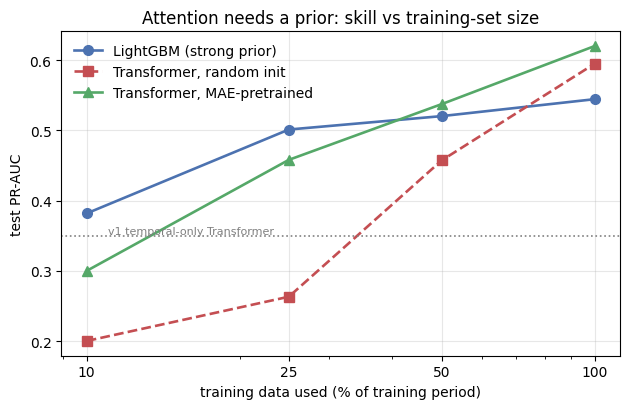

saved -> /content/drive/MyDrive/MSc Dissertation/ciew_v5_cache/fig_scaling.png


In [27]:
if RUN_SCALING and scaling:
    SC = pd.DataFrame(scaling)
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    styles = {"lightgbm": ("o-", "#4C72B0", "LightGBM (strong prior)"),
              "scratch": ("s--", "#C44E52", "Transformer, random init"),
              "pretrained": ("^-", "#55A868", "Transformer, MAE-pretrained")}
    for k, (st, c, lab) in styles.items():
        ax.plot(SC.frac * 100, SC[k], st, color=c, lw=1.9, ms=7, label=lab)
    ax.axhline(0.349, ls=":", c="grey", lw=1.2)
    ax.text(11, 0.353, "v1 temporal-only Transformer", fontsize=8, color="grey")
    ax.set_xscale("log"); ax.set_xticks([10, 25, 50, 100])
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_xlabel("training data used (% of training period)")
    ax.set_ylabel("test PR-AUC")
    ax.set_title("Attention needs a prior: skill vs training-set size")
    ax.legend(frameon=False); ax.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(CFG.CACHE / "fig_scaling.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("saved ->", CFG.CACHE / "fig_scaling.png")

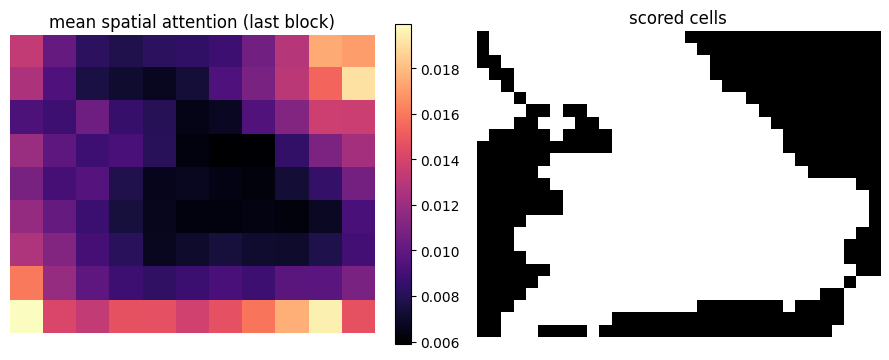

In [28]:
@torch.no_grad()
def spatial_attention(net, loader, n_cases=64):
    """Mean attention received by each spatial patch in the last block, on high-confidence hits."""
    net.eval()
    store = []
    blk = net.enc.blocks[-1]
    feats = {}
    def hook(mod, inp, out):
        feats["x"] = inp[0].detach()
    h = blk.att_s.qkv.register_forward_hook(hook)
    seen = 0
    for xb, yo, ym, yr, ya, yd in loader:
        xb = xb.to(DEVICE)
        with torch.cuda.amp.autocast(enabled=AMP):
            o, _, _, _, _, _ = net(xb)
        p = torch.sigmoid(o.float())
        hit = ((p > 0.5).float() * yo.to(DEVICE)).flatten(1).sum(1) > 0
        if hit.any():
            x = feats["x"].float()                       # (B*nt, ns, d)
            qkv = blk.att_s.qkv(x)
            B_, ns, _ = x.shape
            hd = blk.att_s.h; dh = blk.att_s.dh
            qkv = qkv.reshape(B_, ns, 3, hd, dh).permute(2, 0, 3, 1, 4)
            att = (qkv[0] @ qkv[1].transpose(-2, -1)) * blk.att_s.scale
            att = att.softmax(-1).mean(1).mean(1)        # (B_, ns) attention received
            att = att.reshape(-1, net.enc.nt, ns)[hit.cpu().numpy()]
            store.append(att[:, -1, :].cpu().numpy())    # most recent timestep
            seen += int(hit.sum())
        if seen >= n_cases:
            break
    h.remove()
    if not store:
        return None
    a = np.concatenate(store).mean(0)
    return a.reshape(net.enc.gh, net.enc.gw)

A = spatial_attention(RESULTS["CIEW v4 (MAE-pretrained)"], dl_te)
if A is not None:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    im = axes[0].imshow(A[::-1], cmap="magma")
    axes[0].set_title("mean spatial attention (last block)"); axes[0].axis("off")
    plt.colorbar(im, ax=axes[0], fraction=.046)
    axes[1].imshow(LAND[::-1], cmap="Greys_r"); axes[1].set_title("scored cells"); axes[1].axis("off")
    plt.tight_layout(); plt.savefig(CFG.CACHE / "fig_attention.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("no high-confidence hits captured — lower the threshold or train longer")

In [29]:
manifest = {
    "mode": MODE,
    "domain": {"H": int(H), "W": int(W), "scored_cells": int(N_LAND)},
    "record": [str(times[0]), str(times[-1])], "T": int(T),
    "channels": CH_NAMES,
    "tokens": {"time": int(HIST_T), "space": int(model.enc.ns)},
    "params_millions": round(n_par / 1e6, 2),
    "base_rate_test": float(OCC[te_o][:, LAND].mean()),
    "val_pr_auc": {"pretrained": float(best_pre), "scratch": float(best_scr)},
    "test_table": tab.to_dict(orient="index"),
    "scaling": scaling,
}
with open(CFG.CACHE / "ciew_v4_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print(json.dumps({k: v for k, v in manifest.items() if k != "test_table"}, indent=2, default=str))
print("\nartefacts in", CFG.CACHE)
for p in sorted(CFG.CACHE.glob("*")):
    print("  ", p.name)

{
  "mode": "real",
  "domain": {
    "H": 25,
    "W": 33,
    "scored_cells": 520
  },
  "record": [
    "2015-01-01 00:00:00",
    "2026-06-30 19:00:00"
  ],
  "T": 100772,
  "channels": [
    "u10",
    "v10",
    "u100",
    "v100",
    "ws10",
    "ws100",
    "shear",
    "msl",
    "msl_grad",
    "msl_lap",
    "msl_tend3",
    "geos",
    "sp",
    "cape",
    "wmaxshear",
    "kx",
    "tcwv",
    "blh",
    "t2m",
    "dewdep",
    "gust",
    "gust_lag24",
    "sin_doy",
    "cos_doy",
    "sin_hod",
    "cos_hod",
    "adv",
    "log_tsl",
    "log_prev_ia",
    "roll7",
    "roll30",
    "adi_map",
    "cv2_map",
    "evrate_map"
  ],
  "tokens": {
    "time": 16,
    "space": 99
  },
  "params_millions": 8.91,
  "base_rate_test": 0.07681795954704285,
  "val_pr_auc": {
    "pretrained": 0.6320957585264874,
    "scratch": 0.6081940478460972
  },
  "scaling": [
    {
      "frac": 0.1,
      "n_origins": 2349,
      "scratch": 0.20019777637609895,
      "pretrained": 0.300